# Classificação do desempenho de cursos no ENADE 2023 e fatores associados

**Ciência de Dados (T326) · UNIFOR · Profa. Dra. Cynthia Moreira Maia**
**Equipe:** Nicolas Simões Leão Santos · Gisele Costa Siqueira · Silvio Bruno do Nascimento Lima · Marcos Vinicius Herbster · Luiz Eduardo Alves

Este notebook reúne o código das **Sprints 1, 2 e 3** do projeto de extensão. A ideia central do trabalho é: **dado um curso de graduação, classificar se a sua nota média no ENADE 2023 fica acima ou abaixo da mediana da sua área**, a partir do perfil médio dos concluintes e das características do curso, e identificar quais fatores acompanham os cursos de melhor desempenho.

| Parte | Sprint | Seções do relatório atendidas |
|---|---|---|
| **Parte 1** | Sprint 1 – Análise exploratória | 3.1 Base de dados · 4.1 Parte 1 – Análise Exploratória dos Dados |
| **Parte 2** | Sprint 2 – Preparação dos dados | 3.2 Pré-processamento |
| **Parte 3** | Sprint 3 – Algoritmos individuais | 3.3 Divisão dos dados · 3.4 Algoritmos individuais · 3.7 Métricas de avaliação · 4.2 Parte 2 – Algoritmos individuais |

**Como executar**
1. Baixe os *Microdados do Enade 2023* no site do INEP (https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enade) e deixe o arquivo `microdados_enade_2023.zip` na mesma pasta deste notebook (ou defina a variável de ambiente `ENADE_ZIP` com o caminho). **Não é preciso descompactar.**
2. Instale as dependências: `pip install -r requirements.txt`.
3. Execute todas as células (`Run All`). O notebook lê os 32 arquivos direto do `.zip`; a execução completa leva alguns minutos, e as figuras são salvas na pasta `figuras/`.

> **Fora do notebook:** o quadro Kanban no Trello, o registro no Dreamshaper, a Seção 2.7 (Trabalhos Relacionados) e a redação do documento seguem o modelo de relatório e não são geradas aqui. As tabelas e figuras deste notebook alimentam as seções 3.x e 4.x desse documento.

In [1]:
import os, io, re, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40, "display.width", 170, "display.float_format", "{:,.3f}".format)
# Paleta: azul = principal / "acima da mediana"; laranja = contraste / "abaixo da mediana"; cinza = neutro
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8a87"
sns.set_theme(style="whitegrid", context="notebook", palette=[AZUL, LARANJA, "#1baf7a"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False, "grid.linewidth": 0.5, "grid.alpha": 0.6,
                     "axes.titlelocation": "left", "legend.frameon": False})

RANDOM_STATE = 42
ZIP_PATH = os.environ.get("ENADE_ZIP", "microdados_enade_2023.zip")
FIG_DIR = "figuras"; os.makedirs(FIG_DIR, exist_ok=True)
assert os.path.exists(ZIP_PATH), (f"Arquivo '{ZIP_PATH}' não encontrado. Baixe os microdados do ENADE 2023 no site do INEP "
                                   "e coloque o .zip ao lado do notebook (ou defina ENADE_ZIP).")

DADOS = "Microdados_Enade_2023/DADOS/microdados2023_arq{}.txt"
def ler_arq(i, **kw):
    """Lê o arquivo i (1..32) direto do .zip. Tudo como texto; célula vazia vira NaN."""
    with zipfile.ZipFile(ZIP_PATH) as z, z.open(DADOS.format(i)) as f:
        return pd.read_csv(f, sep=";", dtype=str, encoding="latin-1", **kw)

def salvar(nome):
    plt.savefig(os.path.join(FIG_DIR, nome), bbox_inches="tight"); plt.show()
print("Pronto. Arquivo de dados:", os.path.basename(ZIP_PATH), f"({os.path.getsize(ZIP_PATH)/1e6:.0f} MB)")

Pronto. Arquivo de dados: microdados_enade_2023.zip (44 MB)


### Dicionários de códigos
Os microdados trazem **códigos**. Os nomes abaixo vêm do *Dicionário de variáveis* e do *Questionário do Estudante* que acompanham a base (as alternativas do questionário foram extraídas do PDF oficial).

In [2]:
AREAS = {'5': 'Medicina Veterinária', '6': 'Odontologia', '12': 'Medicina', '17': 'Agronomia', '19': 'Farmácia', '21': 'Arquitetura e Urbanismo', '23': 'Enfermagem', '27': 'Fonoaudiologia', '28': 'Nutrição', '36': 'Fisioterapia', '51': 'Zootecnia', '55': 'Biomedicina', '69': 'Tecnologia em Radiologia', '90': 'Tecnologia em Agronegócios', '91': 'Tecnologia em Gestão Hospitalar', '92': 'Tecnologia em Gestão Ambiental', '95': 'Tecnologia em Estética e Cosmética', '5710': 'Engenharia Civil', '5806': 'Engenharia Elétrica', '5814': 'Engenharia de Controle e Automação', '5902': 'Engenharia Mecânica', '6002': 'Engenharia de Alimentos', '6008': 'Engenharia Química', '6208': 'Engenharia de Produção', '6307': 'Engenharia Ambiental', '6405': 'Engenharia Florestal', '6410': 'Tecnologia em Segurança no Trabalho', '6411': 'Engenharia de Computação I'}
CATEGAD = {"1": "Pública Federal", "2": "Pública Estadual", "3": "Pública Municipal", "4": "Privada com fins lucrativos",
           "5": "Privada sem fins lucrativos", "7": "Especial", "8": "Código 8 (não consta no dicionário)"}
ORGACAD = {"10019": "Centro Federal de Educação Tecnológica", "10020": "Centro Universitário", "10022": "Faculdade",
           "10026": "Instituto Federal", "10028": "Universidade"}
REGIAO = {"1": "Norte", "2": "Nordeste", "3": "Sudeste", "4": "Sul", "5": "Centro-Oeste"}
MODALIDADE = {"0": "EaD", "1": "Presencial"}
UF = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO", "21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE",
      "27": "AL", "28": "SE", "29": "BA", "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR", "42": "SC", "43": "RS", "50": "MS", "51": "MT", "52": "GO", "53": "DF"}
TURNO = {"1": "Matutino", "2": "Vespertino", "3": "Integral", "4": "Noturno"}

# Nome curto de cada pergunta do questionário (QE1..QE26) e rótulo de cada alternativa (ex.: QE_I11_A)
QE_NOME = {1: "Estado civil", 2: "Cor/raça", 3: "Nacionalidade", 4: "Escolaridade do pai", 5: "Escolaridade da mãe", 6: "Com quem mora",
           7: "Pessoas na família", 8: "Renda familiar", 9: "Situação financeira", 10: "Situação de trabalho", 11: "Bolsa/financiamento do curso",
           12: "Auxílio permanência", 13: "Bolsa acadêmica", 14: "Atividade no exterior", 15: "Ingresso por ação afirmativa",
           17: "Escola do ensino médio", 18: "Modalidade do ensino médio", 19: "Quem incentivou a graduação", 20: "Apoio nas dificuldades",
           21: "Família com ensino superior", 22: "Livros lidos no ano", 23: "Horas de estudo/semana", 24: "Idioma estrangeiro na IES",
           25: "Motivo da escolha do curso", 26: "Motivo da escolha da instituição"}
ALT = {
 "QE_I01_A": "Solteiro(a)",
 "QE_I01_B": "Casado(a)",
 "QE_I01_C": "Separado(a) judicialmente/divorciado(a)",
 "QE_I01_D": "Viúvo(a)",
 "QE_I01_E": "Outro",
 "QE_I02_A": "Branca",
 "QE_I02_B": "Preta",
 "QE_I02_C": "Amarela",
 "QE_I02_D": "Parda",
 "QE_I02_E": "Indígena",
 "QE_I02_F": "Não quero declarar",
 "QE_I03_A": "Brasileira",
 "QE_I03_B": "Brasileira naturalizada",
 "QE_I03_C": "Estrangeira",
 "QE_I04_A": "Nenhuma",
 "QE_I04_B": "Ensino Fundamental: 1º ao 5º ano (1ª a 4ª série)",
 "QE_I04_C": "Ensino Fundamental: 6º ao 9º ano (5ª a 8ª série)",
 "QE_I04_D": "Ensino Médio",
 "QE_I04_E": "Ensino Superior - Graduação",
 "QE_I04_F": "Pós-graduação",
 "QE_I05_A": "Nenhuma",
 "QE_I05_B": "Ensino fundamental: 1º ao 5º ano (1ª a 4ª série)",
 "QE_I05_C": "Ensino fundamental: 6º ao 9º ano (5ª a 8ª série)",
 "QE_I05_D": "Ensino médio",
 "QE_I05_E": "Ensino Superior - Graduação",
 "QE_I05_F": "Pós-graduação",
 "QE_I06_A": "Em casa ou apartamento, sozinho",
 "QE_I06_B": "Em casa ou apartamento, com pais e/ou parentes",
 "QE_I06_C": "Em casa ou apartamento, com cônjuge e/ou filhos",
 "QE_I06_D": "Em casa ou apartamento, com outras pessoas (incluindo república)",
 "QE_I06_E": "Em alojamento universitário da própria instituição",
 "QE_I06_F": "Em outros tipos de habitação individual ou coletiva (hotel, hospedaria, pensão ou outro)",
 "QE_I07_A": "Nenhuma",
 "QE_I07_B": "Uma",
 "QE_I07_C": "Duas",
 "QE_I07_D": "Três",
 "QE_I07_E": "Quatro",
 "QE_I07_F": "Cinco",
 "QE_I07_G": "Seis",
 "QE_I07_H": "Sete ou mais",
 "QE_I08_A": "Até 1,5 salário mínimo (até R$ 1.980,00)",
 "QE_I08_B": "De 1,5 a 3 salários mínimos",
 "QE_I08_C": "De 3 a 4,5 salários mínimos",
 "QE_I08_D": "De 4,5 a 6 salários mínimos",
 "QE_I08_E": "De 6 a 10 salários mínimos",
 "QE_I08_F": "De 10 a 30 salários mínimos",
 "QE_I08_G": "Acima de 30 salários mínimos (mais de R$ 39.600,00)",
 "QE_I09_A": "Não tenho renda e meus gastos são financiados por programas governamentais",
 "QE_I09_B": "Não tenho renda e meus gastos são financiados pela minha família ou por outras pessoas",
 "QE_I09_C": "Tenho renda, mas recebo ajuda da família ou de outras pessoas para financiar meus gastos",
 "QE_I09_D": "Tenho renda e não preciso de ajuda para financiar meus gastos",
 "QE_I09_E": "Tenho renda e contribuo com o sustento da família",
 "QE_I09_F": "Sou o principal responsável pelo sustento da família",
 "QE_I10_A": "Não estou trabalhando",
 "QE_I10_B": "Trabalho eventualmente",
 "QE_I10_C": "Trabalho até 20 horas semanais",
 "QE_I10_D": "Trabalho de 21 a 39 horas semanais",
 "QE_I10_E": "Trabalho 40 horas semanais ou mais",
 "QE_I11_A": "Nenhum, pois meu curso é gratuito",
 "QE_I11_B": "Nenhum, embora meu curso não seja gratuito",
 "QE_I11_C": "ProUni integral",
 "QE_I11_D": "ProUni parcial, apenas",
 "QE_I11_E": "FIES, apenas",
 "QE_I11_F": "ProUni Parcial e FIES",
 "QE_I11_G": "Bolsa oferecida por governo estadual, distrital ou municipal",
 "QE_I11_H": "Bolsa oferecida pela própria instituição",
 "QE_I11_I": "Bolsa oferecida por outra entidade (empresa, ONG, outra)",
 "QE_I11_J": "Financiamento oferecido pela própria instituição",
 "QE_I11_K": "Financiamento bancário",
 "QE_I12_A": "Nenhum",
 "QE_I12_B": "Auxílio moradia",
 "QE_I12_C": "Auxílio alimentação",
 "QE_I12_D": "Auxílio moradia e alimentação",
 "QE_I12_E": "Auxílio permanência",
 "QE_I12_F": "Outro tipo de auxílio",
 "QE_I13_A": "Nenhum",
 "QE_I13_B": "Bolsa de iniciação científica",
 "QE_I13_C": "Bolsa de extensão",
 "QE_I13_D": "Bolsa de monitoria/tutoria",
 "QE_I13_E": "Bolsa PET",
 "QE_I13_F": "Outro tipo de bolsa acadêmica",
 "QE_I14_A": "Não participei",
 "QE_I14_B": "Sim, Programa Ciência sem Fronteiras",
 "QE_I14_C": "Sim, programa de intercâmbio financiado pelo Governo Federal (Marca; Brafitec; PLI; outro)",
 "QE_I14_D": "Sim, programa de intercâmbio financiado pelo Governo Estadual",
 "QE_I14_E": "Sim, programa de intercâmbio da minha instituição",
 "QE_I14_F": "Sim, outro intercâmbio não institucional",
 "QE_I15_A": "Não",
 "QE_I15_B": "Sim, por critério étnico-racial",
 "QE_I15_C": "Sim, por critério de renda",
 "QE_I15_D": "Sim, por ter estudado em escola pública ou particular com bolsa de estudos",
 "QE_I15_E": "Sim, por sistema que combina dois ou mais critérios anteriores",
 "QE_I15_F": "Sim, por sistema diferente dos anteriores",
 "QE_I17_A": "Todo em escola pública",
 "QE_I17_B": "Todo em escola privada (particular)",
 "QE_I17_C": "Todo no exterior",
 "QE_I17_D": "A maior parte em escola pública",
 "QE_I17_E": "A maior parte em escola privada (particular)",
 "QE_I17_F": "Parte no Brasil e parte no exterior",
 "QE_I18_A": "Ensino médio tradicional",
 "QE_I18_B": "Profissionalizante técnico (eletrônica, contabilidade, agrícola, outro)",
 "QE_I18_C": "Profissionalizante magistério (Curso Normal)",
 "QE_I18_D": "Educação de Jovens e Adultos (EJA) e/ou Supletivo",
 "QE_I18_E": "Outra modalidade",
 "QE_I19_A": "Ninguém",
 "QE_I19_B": "Pais",
 "QE_I19_C": "Outros membros da família que não os pais",
 "QE_I19_D": "Professores",
 "QE_I19_E": "Líder ou representante religioso",
 "QE_I19_F": "Colegas/Amigos",
 "QE_I19_G": "Outras pessoas",
 "QE_I20_A": "Não tive dificuldade",
 "QE_I20_B": "Não recebi apoio para enfrentar dificuldades",
 "QE_I20_C": "Pais",
 "QE_I20_D": "Avós",
 "QE_I20_E": "Irmãos, primos ou tios",
 "QE_I20_F": "Líder ou representante religioso",
 "QE_I20_G": "Colegas de curso ou amigos",
 "QE_I20_H": "Professores do curso",
 "QE_I20_I": "Profissionais do serviço de apoio ao estudante da IES",
 "QE_I20_J": "Colegas de trabalho",
 "QE_I20_K": "Outro grupo",
 "QE_I21_A": "Sim",
 "QE_I21_B": "Não",
 "QE_I22_A": "Nenhum",
 "QE_I22_B": "Um ou dois",
 "QE_I22_C": "De três a cinco",
 "QE_I22_D": "De seis a oito",
 "QE_I22_E": "Mais de oito",
 "QE_I23_A": "Nenhuma, apenas assisto às aulas",
 "QE_I23_B": "De uma a três",
 "QE_I23_C": "De quatro a sete",
 "QE_I23_D": "De oito a doze",
 "QE_I23_E": "Mais de doze",
 "QE_I24_A": "Sim, somente na modalidade presencial",
 "QE_I24_B": "Sim, somente na modalidade semipresencial",
 "QE_I24_C": "Sim, parte na modalidade presencial e parte na modalidade semipresencial",
 "QE_I24_D": "Sim, na modalidade a distância",
 "QE_I24_E": "Não",
 "QE_I25_A": "Inserção no mercado de trabalho",
 "QE_I25_B": "Influência familiar",
 "QE_I25_C": "Valorização profissional",
 "QE_I25_D": "Prestígio Social",
 "QE_I25_E": "Vocação",
 "QE_I25_F": "Oferecido na modalidade a distância",
 "QE_I25_G": "Baixa concorrência para ingresso",
 "QE_I25_H": "Outro motivo",
 "QE_I26_A": "Gratuidade",
 "QE_I26_B": "Preço da mensalidade",
 "QE_I26_C": "Proximidade da minha residência",
 "QE_I26_D": "Proximidade do meu trabalho",
 "QE_I26_E": "Facilidade de acesso",
 "QE_I26_F": "Qualidade/reputação",
 "QE_I26_G": "Foi a única onde tive aprovação",
 "QE_I26_H": "Possibilidade de ter bolsa de estudo",
 "QE_I26_I": "Outro motivo"
}
OUTROS = {"pct_feminino": "% de mulheres", "idade_media": "Idade média (anos)", "anos_entre_em_e_grad": "Anos entre o ensino médio e a graduação",
          "anos_de_curso": "Anos desde o ingresso na graduação", "n_inscritos": "Nº de concluintes inscritos",
          "log_n_inscritos": "log(1 + nº de concluintes inscritos)", "percepcao_media_geral": "Percepção média do curso (1–6)",
          "renda_acima_6sm": "Renda familiar acima de 6 salários mínimos", "mae_superior": "Mãe com ensino superior"}
def rotulo(col, maxlen=62):
    """Nome legível de uma coluna da tabela por curso."""
    if col.endswith("_z") and col[:-2] != col: return rotulo(col[:-2], maxlen) + " (rel. à área)"
    if col in OUTROS: s = OUTROS[col]
    elif col in ALT: s = f"{QE_NOME[int(col[4:6])]}: {ALT[col]}"
    elif col.startswith("turno_"): s = f"Turno {TURNO.get(col[-1], col[-1])}"
    elif col.startswith("media_QE_I"): s = "Percepção, item " + col[-2:] + " (média 1–6)"
    else: s = col
    return s if len(s) <= maxlen else s[: maxlen - 1] + "…"
print(len(ALT), "alternativas de questionário rotuladas | exemplo:", rotulo("QE_I11_A"))

156 alternativas de questionário rotuladas | exemplo: Bolsa/financiamento do curso: Nenhum, pois meu curso é gratui…


---
# PARTE 1 · Sprint 1 — Análise exploratória da base de dados
*(Seção 3.1 – Base de dados · Seção 4.1 – Parte 1: Análise Exploratória dos Dados)*

## 1.1 Descrição geral da base (Seção 3.1)

| Item | Descrição |
|---|---|
| **Nome** | Microdados do Enade 2023 |
| **Fonte** | INEP – Instituto Nacional de Estudos e Pesquisas Educacionais Anísio Teixeira (dados abertos): https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enade |
| **Contexto** | O Exame Nacional de Desempenho dos Estudantes (Enade) avalia, no âmbito do Sinaes, os estudantes **concluintes** dos cursos de graduação. A edição 2023 avaliou as áreas de saúde, engenharias, ciências agrárias, arquitetura e alguns cursos tecnológicos. A base reúne a **nota** de cada concluinte, as respostas ao **Questionário do Estudante** (perfil socioeconômico e percepção do curso) e a caracterização do curso. |
| **Objetivo da base** | Medir o desempenho dos concluintes e caracterizar o perfil socioeconômico e a percepção sobre o curso, para subsidiar a avaliação da qualidade dos cursos (Sinaes). |
| **Problema que será investigado** | **Classificação supervisionada binária**, no nível do curso: prever se a **nota média do curso (`NT_GER`) fica acima ou abaixo da mediana da sua área**, a partir do perfil médio dos concluintes e das características do curso. Não é regressão nem *clustering*. |
| **Instâncias** | 406.294 concluintes inscritos (linhas de cada arquivo) agrupados em **9.812 cursos**; 7.723 cursos têm ≥ 10 concluintes com nota válida e são as instâncias da modelagem (Parte 2). |
| **Atributos** | 125 variáveis distintas (123 + `NU_ANO` e `CO_CURSO`): 53 categóricas, 42 ordinais (escala 1–6), 22 numéricas, 6 textuais e 2 identificadores (tabela na seção 1.2). |
| **Formato** | 32 arquivos de texto (`.txt`, separador `;`) dentro de um `.zip`, mais o dicionário de variáveis, o manual do usuário e o questionário. |
| **Estrutura** | Cada arquivo traz um **grupo de variáveis** (curso, dados acadêmicos, notas, percepção do curso, sexo, idade e uma pergunta do questionário por arquivo). |
| **Restrição de privacidade (LGPD)** | Para dificultar a reidentificação, o INEP **ordena cada arquivo por variáveis distintas**: a linha *k* de um arquivo não é o mesmo aluno da linha *k* de outro. Só é possível juntar os arquivos pelo **código do curso (`CO_CURSO`)**. |

O inventário e a verificação da restrição de privacidade são feitos abaixo.

In [3]:
# Inventário dos 32 arquivos (lidos em blocos): conteúdo, nº de variáveis, nº de linhas, tamanho e valores ausentes por variável
DESCR = {1: "Curso: IES, categoria administrativa, organização acadêmica, área, modalidade, município, UF, região",
         2: "Acadêmico: ano de conclusão do ensino médio, ano de ingresso na graduação, turno",
         3: "Provas: tipo de presença, notas (geral, formação geral, componente específico) e itens",
         4: "Percepção sobre a prova/curso (QE27–QE68, escala de 1 a 6)", 5: "Sexo", 6: "Idade"}
DESCR.update({i: f"Questionário do estudante – QE{i-6:02d}" for i in range(7, 33)})

def tipo_col(c, arq):
    if c in ("NU_ANO", "CO_CURSO"): return "identificador"
    if arq == 4 and c.startswith("QE_I"): return "ordinal (escala 1–6)"
    if c.startswith("NT_") or c in ("NU_IDADE", "ANO_FIM_EM", "ANO_IN_GRAD") or c.startswith("NU_ITEM"): return "numérico"
    if c.startswith("DS_VT"): return "texto (vetor de respostas)"
    return "categórico (código ou alternativa)"

linhas, esquema = [], []
with zipfile.ZipFile(ZIP_PATH) as z:
    for i in range(1, 33):
        info = z.getinfo(DADOS.format(i)); n, nul = 0, None
        with z.open(info) as f:
            for ch in pd.read_csv(f, sep=";", dtype=str, encoding="latin-1", chunksize=100_000):
                n += len(ch); s_ = ch.isna().sum(); nul = s_ if nul is None else nul + s_
        for c, v in nul.items():
            esquema.append({"arq": i, "variável": c, "tipo": tipo_col(c, i), "nulos": int(v), "linhas": n})
        linhas.append({"arquivo": f"arq{i}", "conteúdo": DESCR[i], "variáveis*": len(nul) - 2, "linhas": n, "tamanho (MB)": info.file_size / 1e6})
inventario = pd.DataFrame(linhas); esquema = pd.DataFrame(esquema); esquema["% nulos"] = 100 * esquema["nulos"] / esquema["linhas"]
display(inventario.style.format({"linhas": "{:,.0f}", "tamanho (MB)": "{:.1f}", "variáveis*": "{:.0f}"}).hide(axis="index"))
print("* sem contar NU_ANO e CO_CURSO, que aparecem em todos os arquivos.")
N_ALUNOS = int(inventario["linhas"].iloc[0]); assert inventario["linhas"].nunique() == 1
print(f"Total: {inventario['variáveis*'].sum() + 2} variáveis distintas | {N_ALUNOS:,} concluintes inscritos (linhas por arquivo) | {inventario['tamanho (MB)'].sum():.0f} MB descompactados")

arquivo,conteúdo,variáveis*,linhas,tamanho (MB)
arq1,"Curso: IES, categoria administrativa, organização acadêmica, área, modalidade, município, UF, região",8,"406,294",17.8
arq2,"Acadêmico: ano de conclusão do ensino médio, ano de ingresso na graduação, turno",3,"406,294",10.2
arq3,"Provas: tipo de presença, notas (geral, formação geral, componente específico) e itens",42,"406,294",92.2
arq4,"Percepção sobre a prova/curso (QE27–QE68, escala de 1 a 6)",42,"406,294",37.8
arq5,Sexo,1,"406,294",6.1
arq6,Idade,1,"406,294",6.5
arq7,Questionário do estudante – QE01,1,"406,294",6.1
arq8,Questionário do estudante – QE02,1,"406,294",6.1
arq9,Questionário do estudante – QE03,1,"406,294",6.1
arq10,Questionário do estudante – QE04,1,"406,294",6.1


* sem contar NU_ANO e CO_CURSO, que aparecem em todos os arquivos.
Total: 125 variáveis distintas | 406,294 concluintes inscritos (linhas por arquivo) | 329 MB descompactados


In [4]:
# Verificação da restrição de privacidade: as linhas dos arquivos NÃO correspondem ao mesmo aluno,
# mas a contagem de alunos por curso é idêntica -> a junção só é possível por curso.
chaves = {i: ler_arq(i, usecols=["CO_CURSO"])["CO_CURSO"] for i in [1, 2, 3, 5, 6, 14, 32]}
ref = chaves[1]; ref_cont = ref.value_counts().sort_index()
res = []
for i, s in chaves.items():
    cont = s.value_counts().sort_index()
    res.append({"arquivo": f"arq{i}", "cursos distintos": s.nunique(),
                "mesma contagem de alunos por curso que a arq1?": bool(np.array_equal(cont.index, ref_cont.index) and np.array_equal(cont.values, ref_cont.values)),
                "% de linhas com o mesmo CO_CURSO da arq1 na mesma posição": 100 * float((s.values == ref.values).mean())})
verif = pd.DataFrame(res); display(verif.style.format({"% de linhas com o mesmo CO_CURSO da arq1 na mesma posição": "{:.2f}%"}).hide(axis="index"))

arquivo,cursos distintos,mesma contagem de alunos por curso que a arq1?,% de linhas com o mesmo CO_CURSO da arq1 na mesma posição
arq1,9812,True,100.00%
arq2,9812,True,0.03%
arq3,9812,True,0.02%
arq5,9812,True,0.73%
arq6,9812,True,0.10%
arq14,9812,True,0.02%
arq32,9812,True,0.05%


**Interpretação.** Os 32 arquivos têm o mesmo número de linhas (406.294) e **a mesma quantidade de alunos por curso**, mas a linha *k* de um arquivo quase nunca pertence ao mesmo curso da linha *k* de outro (coincidência de no máximo 0,73%, ou seja, praticamente acaso). O INEP embaralhou cada arquivo, então **não é possível reconstruir a ficha completa de um aluno**: só o código do curso (`CO_CURSO`) é um elo confiável. Essa restrição define o projeto: em vez de prever a nota de um aluno, usamos **o curso como unidade de análise**, descrito pelo *perfil médio* dos seus concluintes.

## 1.2 Instâncias, atributos, tipos e valores ausentes (Seção 3.1)

- **Instâncias:** cada linha de cada arquivo é um **concluinte inscrito** no Enade 2023. Mas, como vimos acima, essa linha não é comparável entre arquivos; a unidade que realmente podemos acompanhar entre os arquivos é o **curso**.
- **Atributos:** o conjunto completo tem as variáveis listadas no inventário. A tabela abaixo as agrupa por **tipo**.
- **Valores ausentes:** contados em cada variável, durante a leitura em blocos.

tipo,variáveis
categórico (código ou alternativa),53
ordinal (escala 1–6),42
numérico,22
texto (vetor de respostas),6
"identificador (NU_ANO, CO_CURSO)",2


bloco,variáveis,variáveis com algum nulo,% nulos (média),% nulos (máx.)
"Cadastro do curso e do aluno (arq1, 2, 5, 6)",13,0,0.0,0.0
Percepção da prova (arq4),42,42,9.5,9.5
Provas e notas (arq3),42,31,5.4,14.7
Questionário do estudante (arq7–32),26,26,9.5,9.5


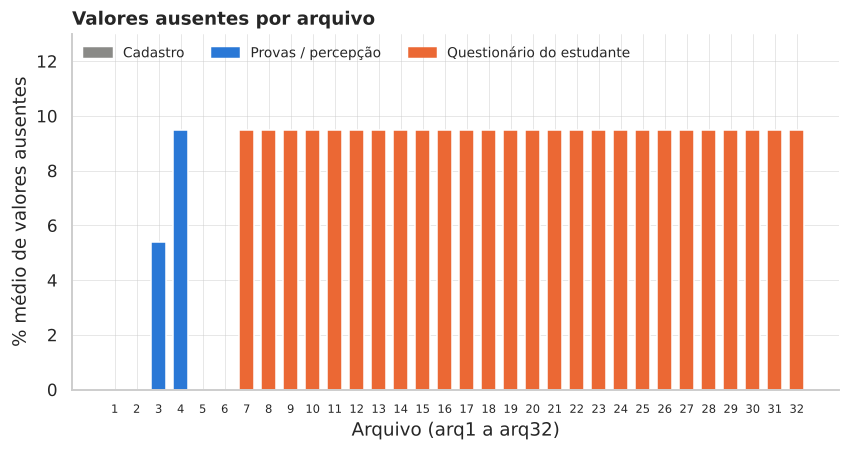

In [5]:
atrib = esquema[esquema["tipo"] != "identificador"]
tipos = (atrib.groupby("tipo").agg(variáveis=("variável", "nunique")).sort_values("variáveis", ascending=False).reset_index())
tipos.loc[len(tipos)] = ["identificador (NU_ANO, CO_CURSO)", 2]
display(tipos.style.hide(axis="index"))

def bloco(a): return ("Cadastro do curso e do aluno (arq1, 2, 5, 6)" if a in (1, 2, 5, 6) else "Provas e notas (arq3)" if a == 3
                      else "Percepção da prova (arq4)" if a == 4 else "Questionário do estudante (arq7–32)")
atrib = atrib.assign(bloco=atrib["arq"].map(bloco))
nul_bloco = (atrib.groupby("bloco").agg(variáveis=("variável", "nunique"), com_nulos=("nulos", lambda s: int((s > 0).sum())),
                                        pct_nulos_medio=("% nulos", "mean"), pct_nulos_max=("% nulos", "max")).reset_index())
display(nul_bloco.rename(columns={"com_nulos": "variáveis com algum nulo", "pct_nulos_medio": "% nulos (média)", "pct_nulos_max": "% nulos (máx.)"})
        .style.format({"% nulos (média)": "{:.1f}", "% nulos (máx.)": "{:.1f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 4.2))
plot_n = atrib.groupby("arq")["% nulos"].mean().reindex(range(1, 33))
cores = [AZUL if a in (3, 4) else LARANJA if a >= 7 else CINZA for a in plot_n.index]
ax.bar([f"{a}" for a in plot_n.index], plot_n.values, color=cores, width=0.7)
ax.set_ylim(0, 13); ax.tick_params(axis="x", labelsize=7.5)
ax.set_xlabel("Arquivo (arq1 a arq32)"); ax.set_ylabel("% médio de valores ausentes")
ax.set_title("Valores ausentes por arquivo")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CINZA, label="Cadastro"), Patch(color=AZUL, label="Provas / percepção"), Patch(color=LARANJA, label="Questionário do estudante")], loc="upper left", ncol=3, fontsize=9)
salvar("01_valores_ausentes.png")

**Interpretação.** O cadastro (arq1, 2, 5 e 6) não tem nenhum valor ausente. O **Questionário do Estudante e a Percepção da prova têm 9,5% de ausentes em todas as perguntas**: o mesmo percentual em todas indica que são os mesmos ≈ 38,6 mil estudantes que não responderam ao questionário, e não lacunas espalhadas. No arquivo de provas (arq3), até 14,7% das notas estão vazias, porque só quem esteve presente com resultado válido tem nota. Consequências: as respostas do questionário serão resumidas **entre quem respondeu**, e as notas existem apenas para parte dos alunos (seção 1.3).

## 1.3 Presença na prova e distribuição das notas

A nota que queremos classificar é `NT_GER` (nota bruta geral, de 0 a 100: 25% formação geral e 75% componente específico). Segundo o manual, só tem **resultado válido** quem tem `TP_PRES = 555`. Primeiro olhamos quem fez a prova de fato.

In [6]:
NOTAS = ["NT_GER", "NT_FG", "NT_CE", "NT_OBJ_FG", "NT_DIS_FG", "NT_OBJ_CE", "NT_DIS_CE"]
a3 = ler_arq(3, usecols=["CO_CURSO", "TP_PRES"] + NOTAS)
a3[NOTAS] = a3[NOTAS].apply(pd.to_numeric, errors="coerce")
PRES = {"222": "Ausente", "334": "Eliminado por participação indevida", "444": "Ausente por dupla graduação", "555": "Presente com resultado válido",
        "565": "Dispensado (sem ensalamento)", "585": "Dispensado (fenômenos da natureza)", "888": "Presente, resultado desconsiderado pelo Inep"}
pres = a3["TP_PRES"].value_counts().rename_axis("TP_PRES").reset_index(name="alunos")
pres["situação"] = pres["TP_PRES"].map(PRES); pres["%"] = 100 * pres["alunos"] / len(a3)
pres["com NT_GER preenchida"] = pres["TP_PRES"].map(a3.groupby("TP_PRES")["NT_GER"].count())
display(pres[["TP_PRES", "situação", "alunos", "%", "com NT_GER preenchida"]].style.format({"alunos": "{:,.0f}", "%": "{:.1f}", "com NT_GER preenchida": "{:,.0f}"}).hide(axis="index"))
valido = (a3["TP_PRES"] == "555") & a3["NT_GER"].notna()
print(f"Alunos com resultado válido (TP_PRES = 555 e NT_GER preenchida): {valido.sum():,} de {len(a3):,} ({100*valido.mean():.1f}%)")
print(f"Alunos sem NT_GER: {a3['NT_GER'].isna().sum():,}")

TP_PRES,situação,alunos,%,com NT_GER preenchida
555,Presente com resultado válido,"346,728",85.3,"346,519"
222,Ausente,"56,734",14.0,0
565,Dispensado (sem ensalamento),"1,251",0.3,0
444,Ausente por dupla graduação,600,0.1,0
334,Eliminado por participação indevida,551,0.1,0
585,Dispensado (fenômenos da natureza),392,0.1,0
888,"Presente, resultado desconsiderado pelo Inep",38,0.0,38


Alunos com resultado válido (TP_PRES = 555 e NT_GER preenchida): 346,519 de 406,294 (85.3%)
Alunos sem NT_GER: 59,737


**Interpretação.** Dos 406.294 inscritos, **85,3% (346.519)** têm resultado válido; 14,0% faltaram (`TP_PRES` = 222) e o restante foi eliminado, dispensado ou teve a nota desconsiderada. Há ainda 209 alunos com presença 555 sem `NT_GER` e 38 com presença 888 que têm nota, mas cujo resultado o Inep desconsiderou; esses casos também ficam de fora. Só os 346.519 alunos válidos entram no cálculo da nota média dos cursos.

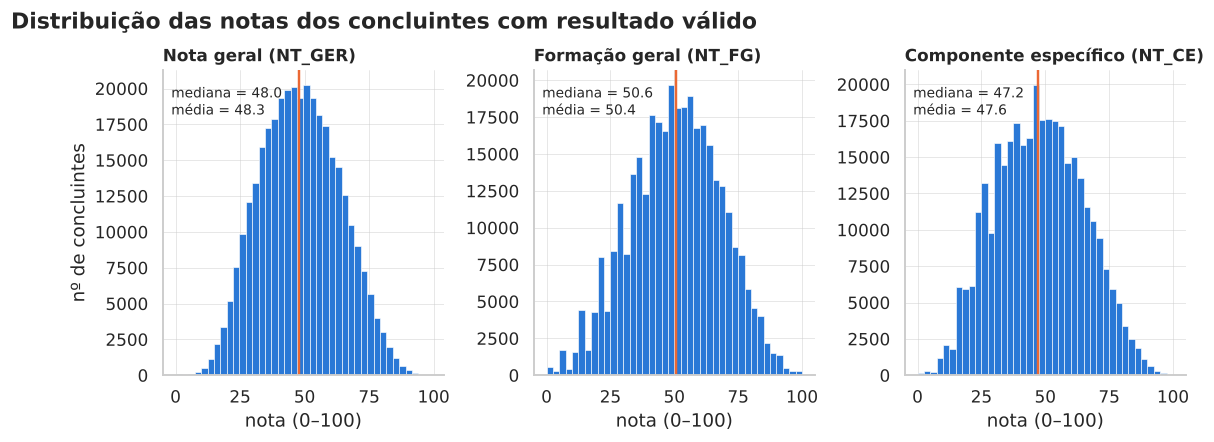

,n,média,dp,min,25%,mediana,75%,max
NT_GER,"346,519",48.286213,15.379917,0.000000,36.800000,48.000000,59.400000,99.000000
NT_FG,"346,519",50.434679,17.555624,0.000000,38.100000,50.600000,63.000000,100.000000
NT_CE,"346,519",47.553085,17.250786,0.000000,34.600000,47.200000,60.200000,100.000000
NT_OBJ_FG,"346,519",53.648078,20.040013,0.000000,44.400000,55.600000,66.700000,100.000000
NT_DIS_FG,"346,519",44.465094,25.116031,0.000000,25.500000,45.300000,63.000000,100.000000
NT_OBJ_CE,"346,519",48.629655,17.187099,0.000000,36.000000,48.000000,60.900000,100.000000
NT_DIS_CE,"346,519",37.807434,32.812805,0.000000,0.000000,36.700000,62.500000,100.000000


In [7]:
v = a3[valido]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=False)
for ax, c, t in zip(axes, ["NT_GER", "NT_FG", "NT_CE"], ["Nota geral (NT_GER)", "Formação geral (NT_FG)", "Componente específico (NT_CE)"]):
    ax.hist(v[c], bins=40, color=AZUL, edgecolor="white", linewidth=0.4)
    ax.axvline(v[c].median(), color=LARANJA, lw=1.6); ax.set_title(t, fontsize=11)
    ax.text(0.03, 0.95, f"mediana = {v[c].median():.1f}\nmédia = {v[c].mean():.1f}", transform=ax.transAxes, ha="left", va="top", fontsize=9)
    ax.set_xlabel("nota (0–100)"); ax.ticklabel_format(axis="y", style="plain")
axes[0].set_ylabel("nº de concluintes")
fig.suptitle("Distribuição das notas dos concluintes com resultado válido", x=0.01, ha="left", fontweight="bold", y=1.03)
fig.subplots_adjust(wspace=0.32)
salvar("02_hist_notas.png")
display(v[NOTAS].describe().T.rename(columns={"count": "n", "mean": "média", "std": "dp", "50%": "mediana"})[["n", "média", "dp", "min", "25%", "mediana", "75%", "max"]]
        .style.format({"n": "{:,.0f}"}))

**Interpretação.** As notas seguem um formato de sino quase simétrico: **média 48,3, mediana 48,0 e desvio padrão 15,4** para a nota geral. A formação geral tem média um pouco maior (50,4) que o componente específico (47,6). A parte discursiva do componente específico (`NT_DIS_CE`) é a mais irregular: média 37,8, desvio 32,8 e pelo menos um quarto dos alunos com nota 0. Como não há caudas pesadas nem assimetria forte, **a média do curso é um bom resumo** do desempenho dos seus alunos e não é preciso transformar a nota. Os "degraus" do histograma da formação geral aparecem porque essa nota é construída com poucas questões.

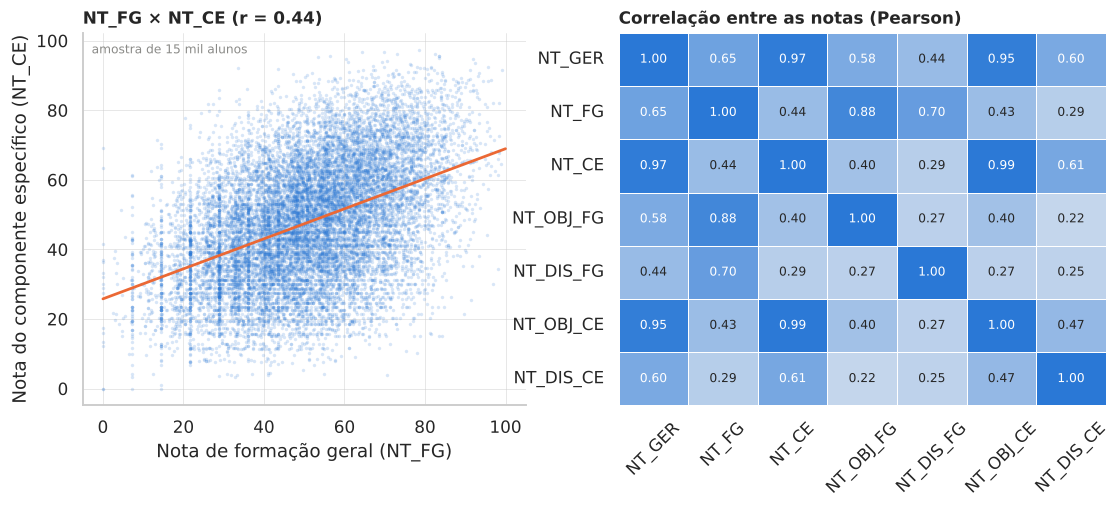

In [8]:
amostra = v.sample(15000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ax.scatter(amostra["NT_FG"], amostra["NT_CE"], s=5, alpha=0.18, color=AZUL, linewidths=0)
b = np.polyfit(v["NT_FG"], v["NT_CE"], 1); xs = np.array([0, 100]); ax.plot(xs, b[0] * xs + b[1], color=LARANJA, lw=1.8)
r = v[["NT_FG", "NT_CE"]].corr().iloc[0, 1]
ax.set_xlabel("Nota de formação geral (NT_FG)"); ax.set_ylabel("Nota do componente específico (NT_CE)")
ax.set_title(f"NT_FG × NT_CE (r = {r:.2f})", fontsize=11); ax.text(0.02, 0.97, "amostra de 15 mil alunos", transform=ax.transAxes, fontsize=8, va="top", color=CINZA)
ax = axes[1]
corr = v[NOTAS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.light_palette(AZUL, as_cmap=True), vmin=0, vmax=1, linewidths=0.5, cbar=False, ax=ax, annot_kws={"fontsize": 8})
ax.set_title("Correlação entre as notas (Pearson)", fontsize=11); ax.tick_params(axis="x", rotation=45)
salvar("03_notas_dispersao_correlacao.png")

**Interpretação.** A nota geral é, na prática, o **componente específico** (correlação 0,97, já que ele vale 75% da nota); a formação geral tem correlação de 0,65 com a nota geral. Entre as duas partes da prova a correlação é moderada (r = 0,44): quem vai bem em formação geral tende a ir bem no específico, mas não é regra, e a nuvem de pontos é bem larga. As faixas verticais do gráfico (perto de 0, 7, 14, 21 e 29) vêm do número pequeno de questões da formação geral. Para o projeto: usamos `NT_GER` como medida única de desempenho, sabendo que ela reflete sobretudo o conteúdo específico de cada área.

## 1.4 Os cursos: tamanho, áreas e características

Como só podemos relacionar os arquivos pelo curso, montamos agora uma tabela **com uma linha por curso** usando os atributos cadastrais (arq1, constantes dentro de cada curso) e a nota média de seus concluintes válidos (arq3). É ainda uma tabela **exploratória**; a tabela final de modelagem é construída na Parte 2.

In [9]:
a1 = ler_arq(1)
ATTRS = ["CO_IES", "CO_CATEGAD", "CO_ORGACAD", "CO_GRUPO", "CO_MODALIDADE", "CO_MUNIC_CURSO", "CO_UF_CURSO", "CO_REGIAO_CURSO"]
assert a1.groupby("CO_CURSO")[ATTRS].nunique().max().max() == 1, "atributos do curso deveriam ser constantes dentro do curso"
cursos = a1.groupby("CO_CURSO")[ATTRS].first()
cursos["n_inscritos"] = a1.groupby("CO_CURSO").size()
g = a3[valido].groupby("CO_CURSO")
cursos["n_validos"] = g.size().reindex(cursos.index).fillna(0).astype(int)
for c in ["NT_GER", "NT_FG", "NT_CE"]: cursos["media_" + c] = g[c].mean()
cursos["area"] = cursos["CO_GRUPO"].map(AREAS); assert cursos["area"].notna().all()
cursos["categoria"] = cursos["CO_CATEGAD"].map(CATEGAD); cursos["regiao"] = cursos["CO_REGIAO_CURSO"].map(REGIAO)
cursos["modalidade"] = cursos["CO_MODALIDADE"].map(MODALIDADE); cursos["organizacao"] = cursos["CO_ORGACAD"].map(ORGACAD)
print(f"{len(cursos):,} cursos | {cursos['CO_IES'].nunique():,} instituições | {cursos['CO_GRUPO'].nunique()} áreas | {cursos['CO_MUNIC_CURSO'].nunique():,} municípios")
print(f"Cursos sem nenhum concluinte válido (sem nota): {(cursos['n_validos']==0).sum()}")
display(pd.DataFrame({"mín.": cursos["n_inscritos"].min(), "mediana": cursos["n_inscritos"].median(), "média": cursos["n_inscritos"].mean(), "máx.": cursos["n_inscritos"].max()},
                     index=["concluintes inscritos por curso"]).style.format("{:,.1f}"))

9,812 cursos | 1,347 instituições | 28 áreas | 718 municípios
Cursos sem nenhum concluinte válido (sem nota): 432


,mín.,mediana,média,máx.
concluintes inscritos por curso,1.0,26.0,41.4,"3,754.0"


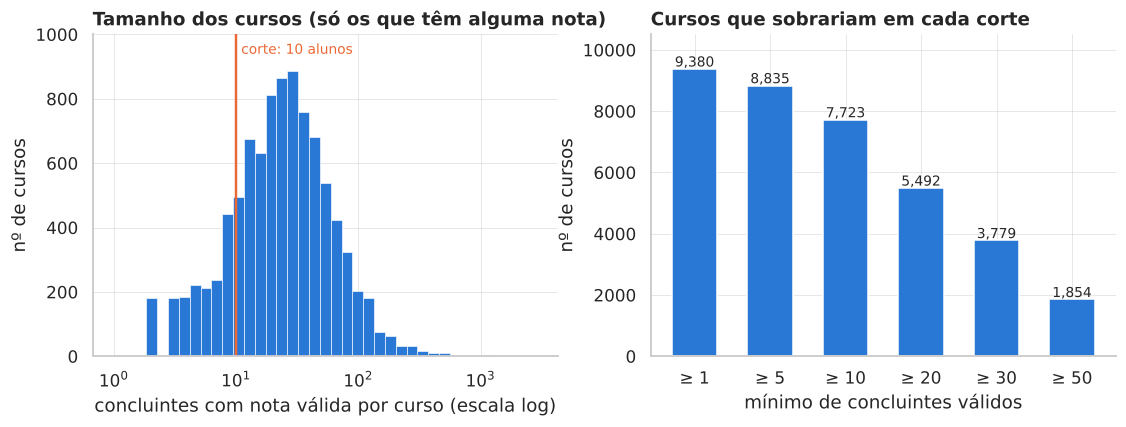

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
com_nota = cursos.loc[cursos["n_validos"] >= 1, "n_validos"]
ax.hist(com_nota, bins=np.logspace(0, np.log10(com_nota.max() + 1), 40), color=AZUL, edgecolor="white", linewidth=0.4)
ax.set_xscale("log"); ax.axvline(10, color=LARANJA, lw=1.6); ax.set_ylim(0, 1000); ax.text(11, 940, "corte: 10 alunos", color=LARANJA, fontsize=9)
ax.set_xlabel("concluintes com nota válida por curso (escala log)"); ax.set_ylabel("nº de cursos"); ax.set_title("Tamanho dos cursos (só os que têm alguma nota)")
ax = axes[1]
lim = [1, 5, 10, 20, 30, 50]
cont = pd.Series({f"≥ {k}": int((cursos["n_validos"] >= k).sum()) for k in lim})
ax.bar(cont.index, cont.values, color=AZUL, width=0.6)
for i, val in enumerate(cont.values): ax.text(i, val + 80, f"{val:,}", ha="center", fontsize=9)
ax.set_ylim(0, cont.max() * 1.12); ax.set_ylabel("nº de cursos"); ax.set_xlabel("mínimo de concluintes válidos"); ax.set_title("Cursos que sobrariam em cada corte")
salvar("04_tamanho_dos_cursos.png")

**Interpretação.** A mediana é de **26 concluintes inscritos por curso** (média 41; o maior curso tem 3.754), então a nota média de cada curso vem de poucos alunos: 432 cursos não têm nenhuma nota válida e 8.835 têm 5 ou mais. Médias calculadas com poucos alunos são instáveis, já que um único aluno com nota 0 ou 90 move bastante a média. O corte de **10 concluintes válidos** mantém 7.723 cursos (82% dos 9.380 que têm alguma nota) e elimina a cauda mais instável; cortes maiores (20 ou 30) deixariam apenas 5.492 e 3.779 cursos.

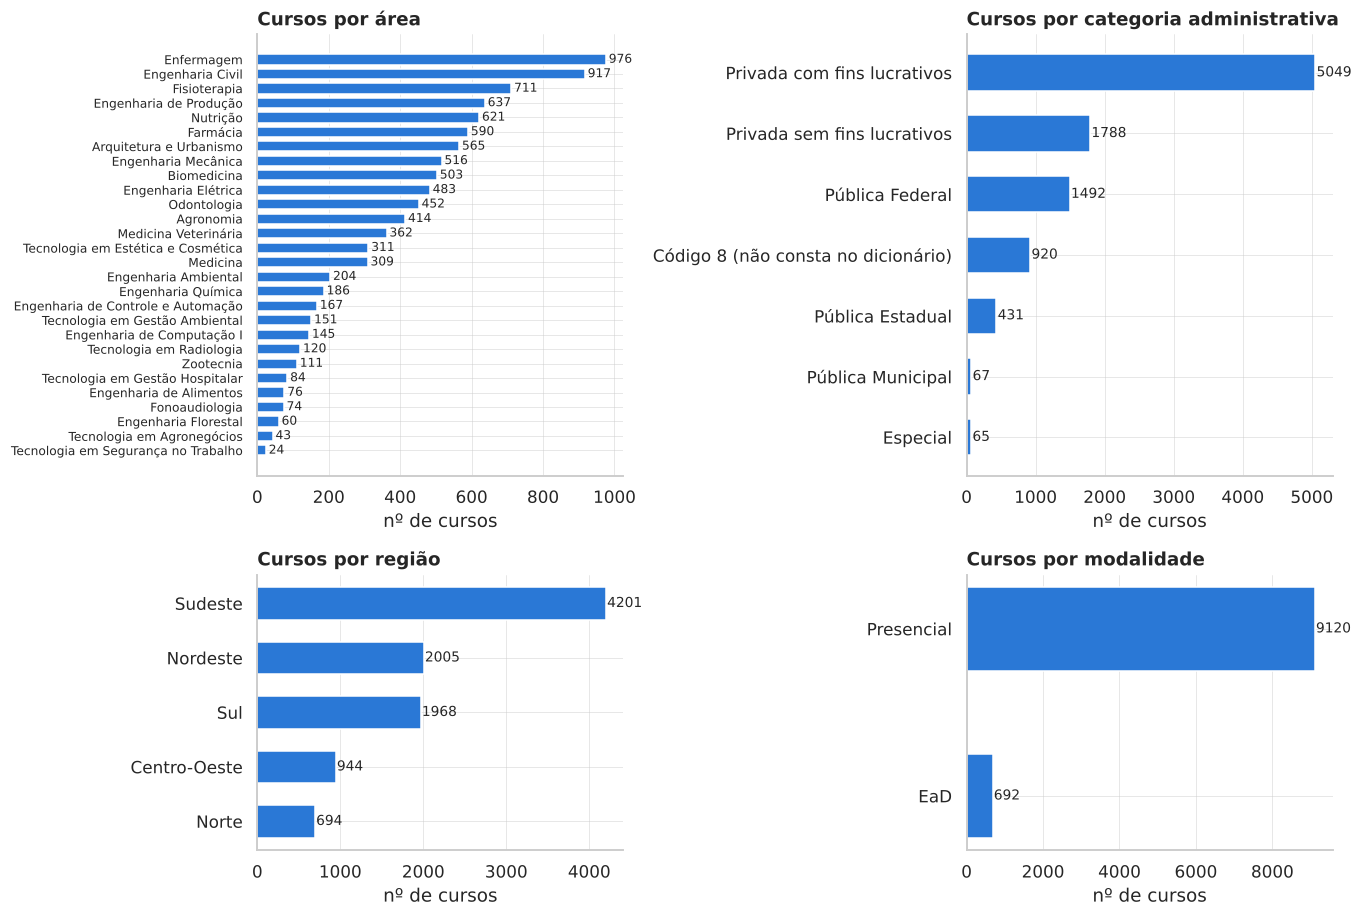

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.5), gridspec_kw={"height_ratios": [1.6, 1]})
ax = axes[0, 0]
vc = cursos["area"].value_counts().sort_values()
ax.barh(vc.index, vc.values, color=AZUL, height=0.7); ax.set_title("Cursos por área"); ax.set_xlabel("nº de cursos")
for i, val in enumerate(vc.values): ax.text(val + 8, i, f"{val}", va="center", fontsize=8)
ax.tick_params(axis="y", labelsize=8)
ax = axes[0, 1]
vc = cursos["categoria"].value_counts().sort_values()
ax.barh(vc.index, vc.values, color=AZUL, height=0.6); ax.set_title("Cursos por categoria administrativa"); ax.set_xlabel("nº de cursos")
for i, val in enumerate(vc.values): ax.text(val + 20, i, f"{val}", va="center", fontsize=9)
ax = axes[1, 0]
vc = cursos["regiao"].value_counts().sort_values()
ax.barh(vc.index, vc.values, color=AZUL, height=0.6); ax.set_title("Cursos por região"); ax.set_xlabel("nº de cursos")
for i, val in enumerate(vc.values): ax.text(val + 15, i, f"{val}", va="center", fontsize=9)
ax = axes[1, 1]
vc = cursos["modalidade"].value_counts().sort_values()
ax.barh(vc.index, vc.values, color=AZUL, height=0.5); ax.set_title("Cursos por modalidade"); ax.set_xlabel("nº de cursos")
for i, val in enumerate(vc.values): ax.text(val + 20, i, f"{val}", va="center", fontsize=9)
plt.tight_layout(); salvar("05_composicao_dos_cursos.png")

**Interpretação.** A base cobre **9.812 cursos de 1.347 instituições e 28 áreas**: só as áreas avaliadas em 2023 (saúde, engenharias, ciências agrárias, arquitetura e alguns tecnólogos); por isso não há, por exemplo, Ciência da Computação ou História. Ao menos 70% dos cursos são privados (51% com fins lucrativos), 93% são presenciais e 43% estão no Sudeste; o Norte tem só 7%. As áreas têm tamanhos muito diferentes, de 976 cursos (Enfermagem) a 24 (Tecnologia em Segurança no Trabalho). Isso importa para a modelagem: (i) a classe "acima da mediana" precisa ser definida **dentro de cada área**; (ii) áreas pequenas terão medianas menos estáveis; (iii) o código 8 de categoria administrativa (920 cursos) não consta no dicionário e foi mantido como uma categoria à parte. Obs.: estes gráficos usam os 9.812 cursos; o filtro de tamanho vem depois.

## 1.5 A nota média dos cursos

Aqui já trabalhamos no nível do curso, só com cursos com **pelo menos 10 concluintes válidos** (corte discutido acima). Cada área faz uma prova diferente; portanto, antes de comparar notas, é preciso saber se as áreas estão na mesma escala.

7,723 cursos com ≥ 10 concluintes válidos


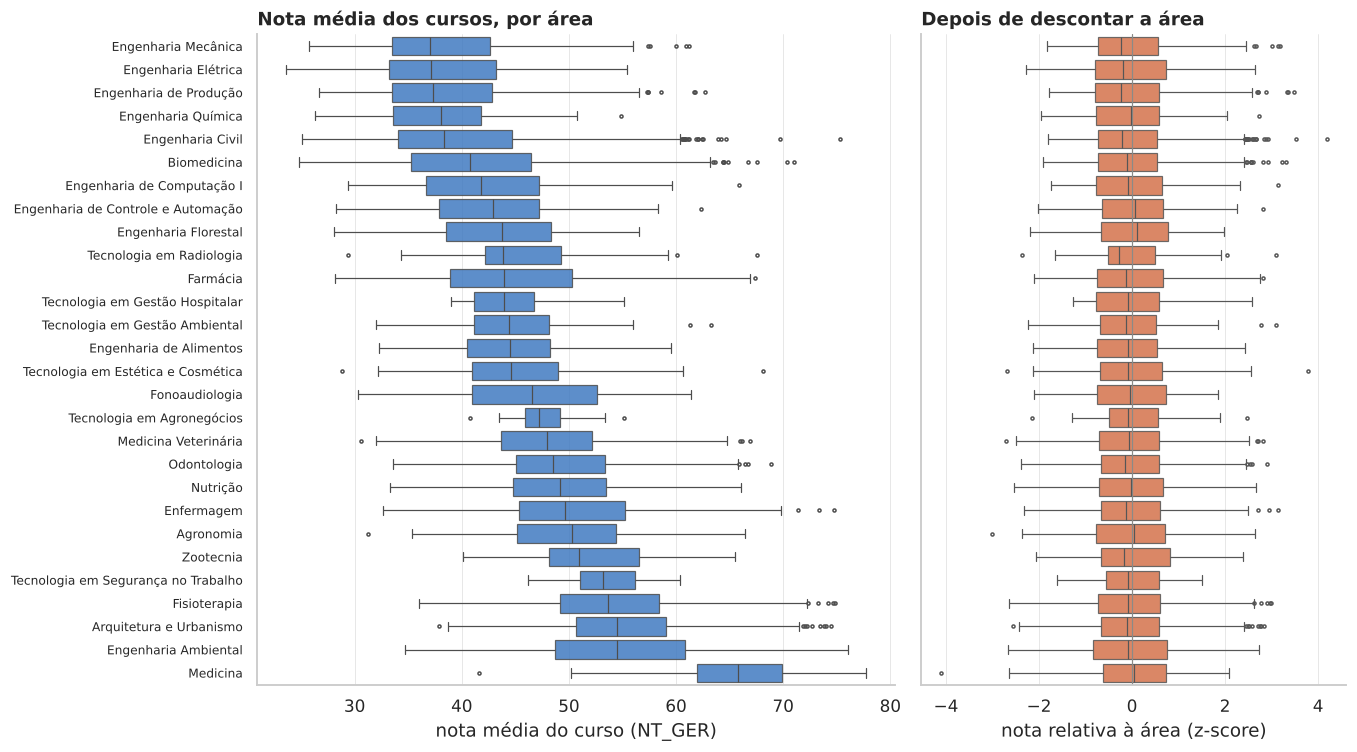

In [12]:
exp = cursos[cursos["n_validos"] >= 10].copy()
exp["media_da_area"] = exp.groupby("CO_GRUPO")["media_NT_GER"].transform("mean")
exp["dp_da_area"] = exp.groupby("CO_GRUPO")["media_NT_GER"].transform("std")
exp["nota_relativa"] = (exp["media_NT_GER"] - exp["media_da_area"]) / exp["dp_da_area"]     # z-score dentro da área (só para exploração)
print(f"{len(exp):,} cursos com ≥ 10 concluintes válidos")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 7), gridspec_kw={"width_ratios": [1.5, 1]})
ordem = exp.groupby("area")["media_NT_GER"].median().sort_values().index
ax = axes[0]
sns.boxplot(data=exp, y="area", x="media_NT_GER", order=ordem, color=AZUL, fliersize=2, linewidth=0.8, ax=ax, boxprops=dict(alpha=0.85))
ax.set_xlabel("nota média do curso (NT_GER)"); ax.set_ylabel(""); ax.set_title("Nota média dos cursos, por área"); ax.tick_params(axis="y", labelsize=8)
ax = axes[1]
sns.boxplot(data=exp, y="area", x="nota_relativa", order=ordem, color=LARANJA, fliersize=2, linewidth=0.8, ax=ax, boxprops=dict(alpha=0.85))
ax.set_yticklabels([]); ax.set_ylabel(""); ax.set_xlabel("nota relativa à área (z-score)"); ax.set_title("Depois de descontar a área"); ax.axvline(0, color=CINZA, lw=0.8)
plt.tight_layout(); salvar("06_notas_por_area.png")

**Interpretação.** **As áreas não estão na mesma escala.** A mediana da nota média dos cursos é 65,8 em Medicina e fica em torno de 37 nas engenharias Mecânica, Elétrica e de Produção: uma diferença de quase 30 pontos, que reflete provas e níveis de dificuldade diferentes e não, necessariamente, a qualidade dos cursos. Comparar notas brutas entre áreas faria quase todos os cursos de Medicina parecerem "bons" e os de Engenharia "ruins". Por isso a variável-alvo é definida **dentro da área** (painel da direita: depois de descontar a média e o desvio de cada área, todas ficam centradas em zero, com dispersão parecida). É a resposta à dúvida natural de que "cursos de áreas diferentes são realmente diferentes": nunca os comparamos diretamente.

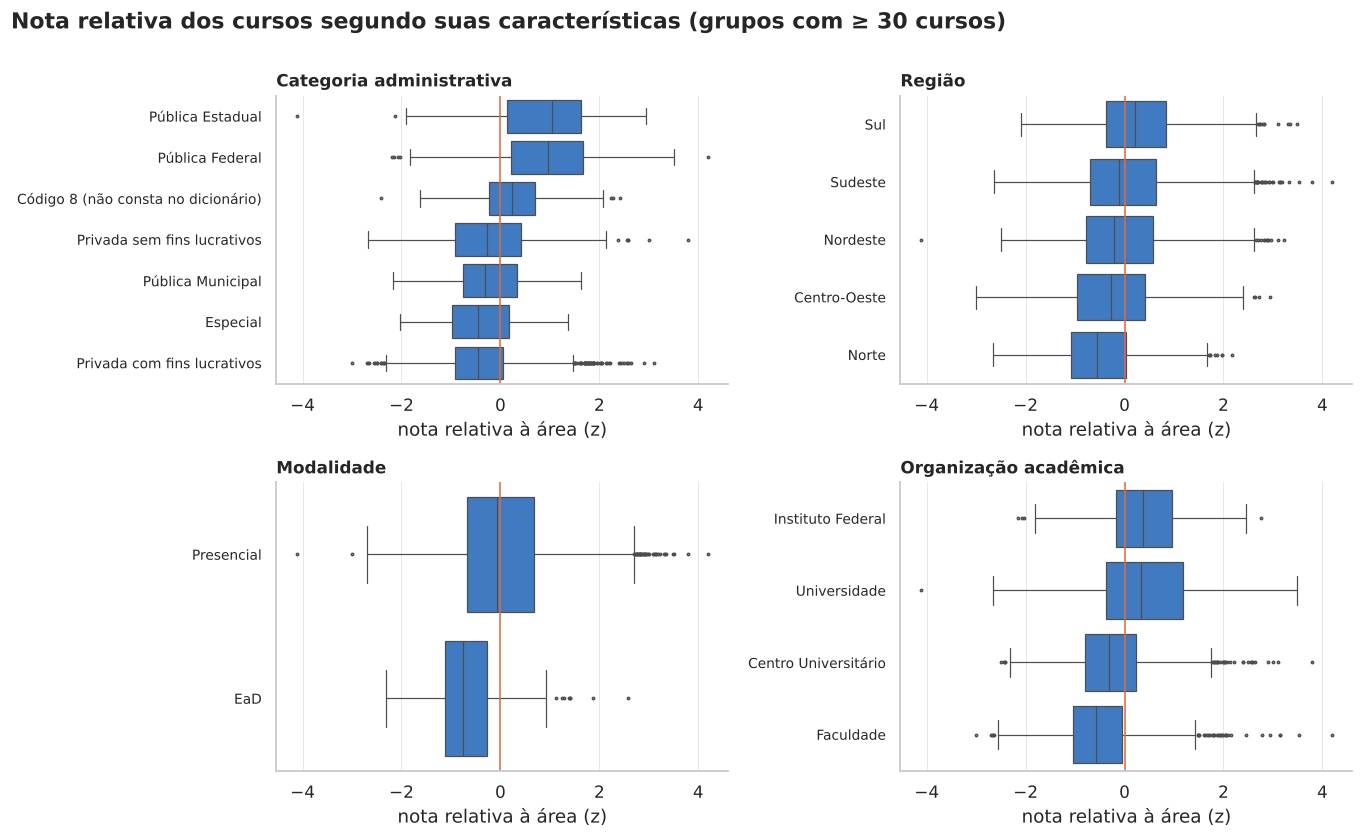

In [13]:
CARACT = [("categoria", "Categoria administrativa"), ("regiao", "Região"), ("modalidade", "Modalidade"), ("organizacao", "Organização acadêmica")]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.6))
tabs = []
for ax, (col, titulo) in zip(axes.ravel(), CARACT):
    d = exp.groupby(col).filter(lambda x: len(x) >= 30)
    ordem = d.groupby(col)["nota_relativa"].median().sort_values(ascending=False).index
    sns.boxplot(data=d, y=col, x="nota_relativa", order=ordem, orient="h", color=AZUL, fliersize=1.5, linewidth=0.8, ax=ax)
    ax.axvline(0, color=LARANJA, lw=1); ax.set_title(titulo, fontsize=11); ax.set_ylabel(""); ax.set_xlabel("nota relativa à área (z)"); ax.tick_params(axis="y", labelsize=9)
    tabs.append(d.groupby(col)["nota_relativa"].agg(cursos="count", mediana="median", média="mean").loc[ordem].assign(característica=titulo).rename_axis("grupo").reset_index())
fig.suptitle("Nota relativa dos cursos segundo suas características (grupos com ≥ 30 cursos)", x=0.01, ha="left", fontweight="bold", y=1.0)
plt.tight_layout(); salvar("07_nota_relativa_por_caracteristica.png")
tab_carac = pd.concat(tabs)[["característica", "grupo", "cursos", "mediana", "média"]].set_index(["característica", "grupo"])
display(tab_carac.style.format({"cursos": "{:,.0f}", "mediana": "{:+.2f}", "média": "{:+.2f}"}))

**Interpretação.** Mesmo dentro da área, **as características do curso se associam à nota**: cursos públicos federais e estaduais têm nota relativa mediana de ≈ +1,0 desvio padrão em relação à média da sua área, enquanto os privados com fins lucrativos ficam em −0,46 e as faculdades em −0,57. Cursos EaD (mediana −0,75) ficam abaixo dos presenciais (−0,07). Por região, o Sul é o mais alto (+0,21) e o Norte o mais baixo (−0,55). Logo, **categoria, organização, modalidade e região carregam informação útil** para a classificação, mas também se misturam com o perfil dos alunos (por exemplo, instituições públicas recebem estudantes de perfil socioeconômico diferente). Esses efeitos serão sempre lidos como associações, não como causas.

## 1.6 Perfil dos concluintes

Cada gráfico usa um arquivo diferente (portanto os percentuais são calculados **entre quem respondeu** a cada pergunta). As alternativas vêm do Questionário do Estudante.

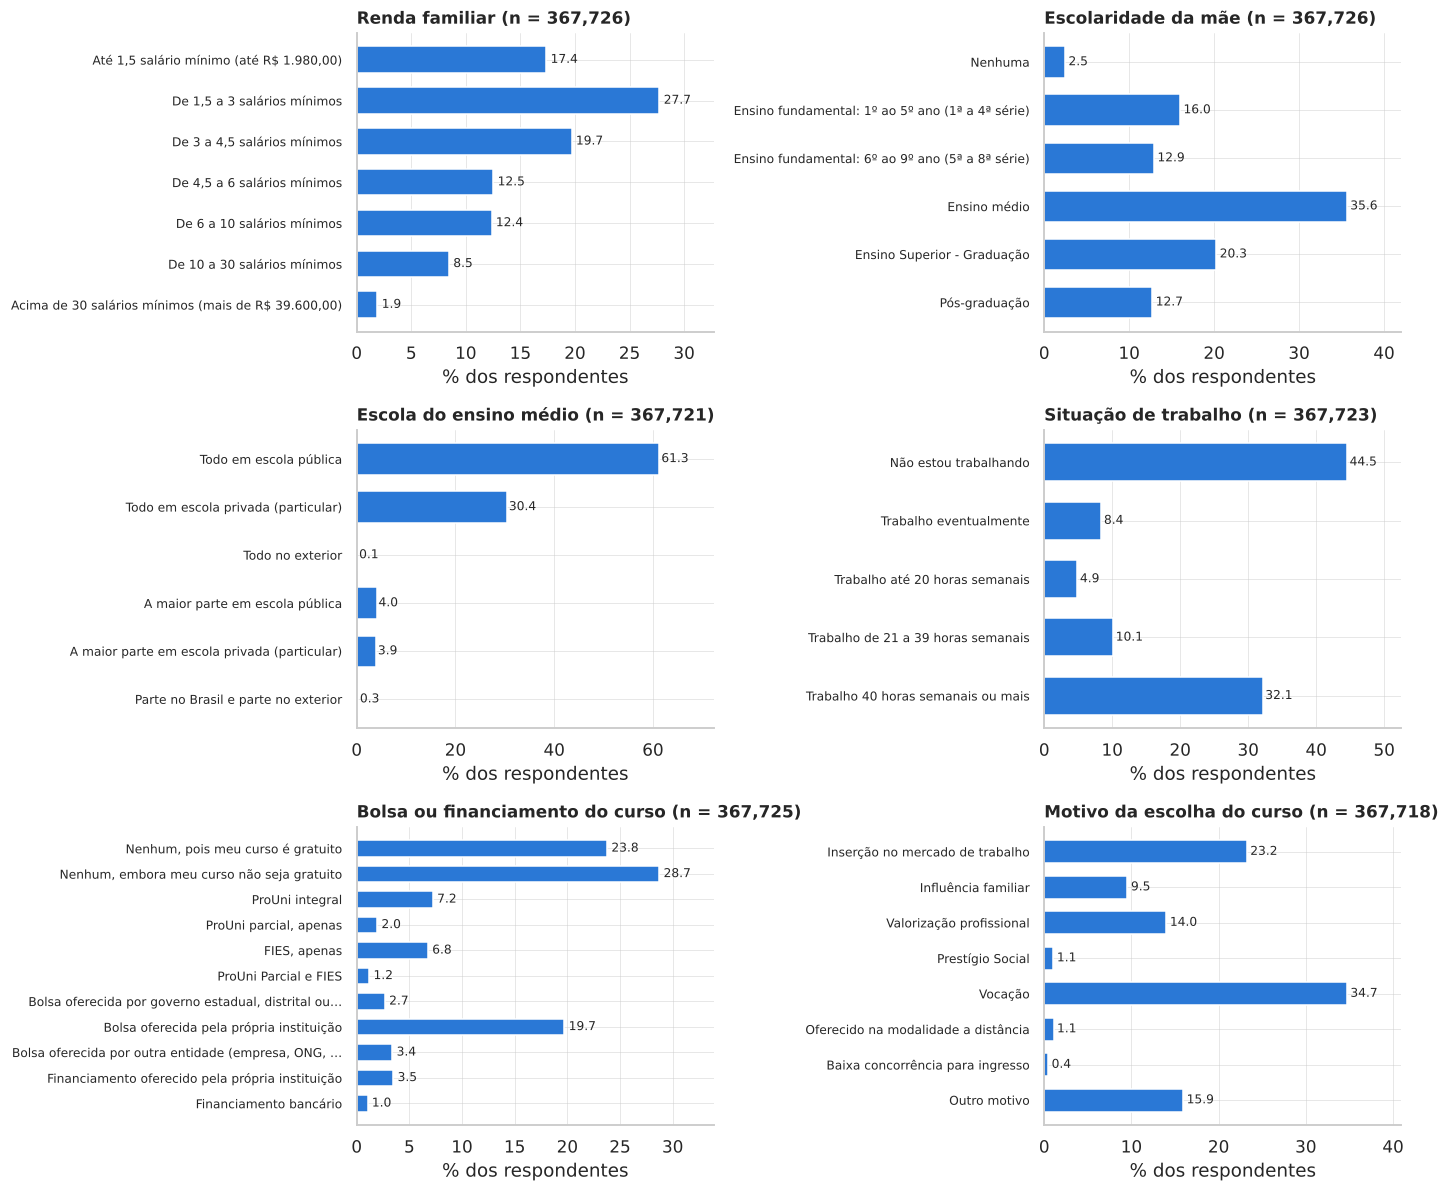

In [14]:
def dist_resposta(i, q):
    d = ler_arq(i, usecols=[q])[q].dropna()
    s = d.value_counts(normalize=True).sort_index() * 100
    s.index = [ALT.get(f"{q}_{k}", k) for k in s.index]; return s, len(d)

perguntas = [(14, "QE_I08", "Renda familiar"), (11, "QE_I05", "Escolaridade da mãe"), (23, "QE_I17", "Escola do ensino médio"),
             (16, "QE_I10", "Situação de trabalho"), (17, "QE_I11", "Bolsa ou financiamento do curso"), (31, "QE_I25", "Motivo da escolha do curso")]
fig, axes = plt.subplots(3, 2, figsize=(13, 11))
for ax, (i, q, t) in zip(axes.ravel(), perguntas):
    s, n = dist_resposta(i, q)
    ax.barh([x if len(x) < 52 else x[:50] + "…" for x in s.index][::-1], s.values[::-1], color=AZUL, height=0.65)
    ax.set_title(f"{t} (n = {n:,})", fontsize=11); ax.set_xlabel("% dos respondentes"); ax.tick_params(axis="y", labelsize=8)
    for k, val in enumerate(s.values[::-1]): ax.text(val + 0.4, k, f"{val:.1f}", va="center", fontsize=8)
    ax.set_xlim(0, s.max() * 1.18)
plt.tight_layout(); salvar("08_perfil_questionario.png")

**Interpretação.** Entre os 367.726 concluintes que responderam ao questionário, **77% vêm de famílias com renda de até 6 salários mínimos**, **61% cursaram todo o ensino médio em escola pública**, 33% têm mãe com ensino superior (20,3% graduação e 12,7% pós) e 32% trabalham 40 horas semanais ou mais (44,5% não trabalham). Quanto ao custeio, 28,7% pagam sem bolsa nem financiamento, 23,8% estudam em curso gratuito e 19,7% têm bolsa da própria instituição. A escolha do curso é sobretudo por vocação (34,7%) e inserção no mercado de trabalho (23,2%). Esse é o perfil que cada curso resume em proporções e que usaremos como atributos. Como os cursos diferem muito nessas proporções (a % de renda alta, por exemplo, vai de perto de 0% a mais de 80%), há variação suficiente para o modelo aproveitar.

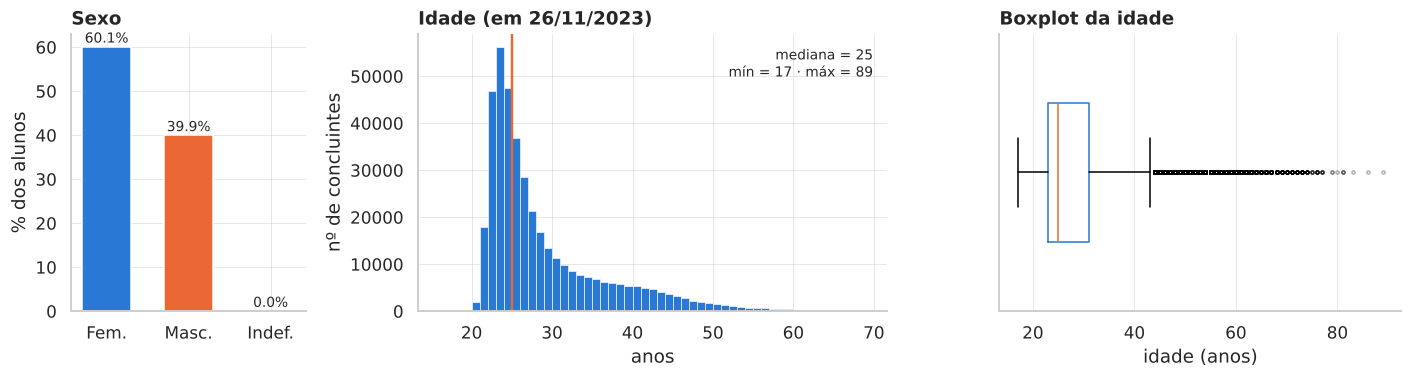

In [15]:
a5 = ler_arq(5, usecols=["TP_SEXO"]); a6 = ler_arq(6, usecols=["NU_IDADE"]); a6["NU_IDADE"] = pd.to_numeric(a6["NU_IDADE"], errors="coerce")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [0.7, 1.4, 1.2]})
ax = axes[0]
sx = a5["TP_SEXO"].map({"F": "Fem.", "M": "Masc.", "9": "Indef."}).value_counts(normalize=True) * 100
ax.bar(sx.index, sx.values, color=[AZUL, LARANJA, CINZA][: len(sx)], width=0.6); ax.set_title("Sexo"); ax.set_ylabel("% dos alunos")
for k, val in enumerate(sx.values): ax.text(k, val + 1, f"{val:.1f}%", ha="center", fontsize=9)
ax = axes[1]
ax.hist(a6["NU_IDADE"].dropna(), bins=np.arange(16, 70, 1), color=AZUL, edgecolor="white", linewidth=0.4)
ax.axvline(a6["NU_IDADE"].median(), color=LARANJA, lw=1.6); ax.set_title("Idade (em 26/11/2023)"); ax.set_xlabel("anos"); ax.set_ylabel("nº de concluintes")
ax.text(0.97, 0.95, f"mediana = {a6['NU_IDADE'].median():.0f}\nmín = {a6['NU_IDADE'].min():.0f} · máx = {a6['NU_IDADE'].max():.0f}", transform=ax.transAxes, ha="right", va="top", fontsize=9)
ax = axes[2]
cor = a6["NU_IDADE"].dropna()
ax.boxplot(cor, vert=False, widths=0.5, flierprops=dict(markersize=2, alpha=0.3), medianprops=dict(color=LARANJA), boxprops=dict(color=AZUL)); ax.set_yticks([])
ax.set_xlabel("idade (anos)"); ax.set_title("Boxplot da idade")
plt.tight_layout(); salvar("09_sexo_idade.png")

**Interpretação.** A maioria dos concluintes é do sexo feminino (60,1%), provavelmente reflexo das áreas de saúde, que dominam a base. A idade é concentrada: **mediana de 25 anos**, a maior parte entre 22 e 30, com cauda longa à direita (o boxplot marca como atípicos os alunos acima de ≈ 43 anos, até 89). Essas idades são plausíveis (adultos que voltaram a estudar) e, segundo o dicionário, vêm da Receita Federal e variam de 17 a 89; por isso **não removemos** nenhuma idade e usamos a idade média do curso, que é pouco sensível a poucos casos extremos.

## 1.7 Problemas de qualidade nos dados

Algumas variáveis são **digitadas pelo estudante** (o próprio dicionário diz *"conforme lançado pelo estudante"*), o que pode gerar valores impossíveis. Verificamos as faixas de valores para decidir o que será tratado na Parte 2.

variável,preenchidos,mínimo,máximo,janela plausível,fora da janela,% fora
ANO_FIM_EM,"406,294",1016,2914,1950–2023,101,0.025
ANO_IN_GRAD,"406,294",4,2090,2000–2023,289,0.071
NU_IDADE,"406,294",17,89,16–90,0,0.000


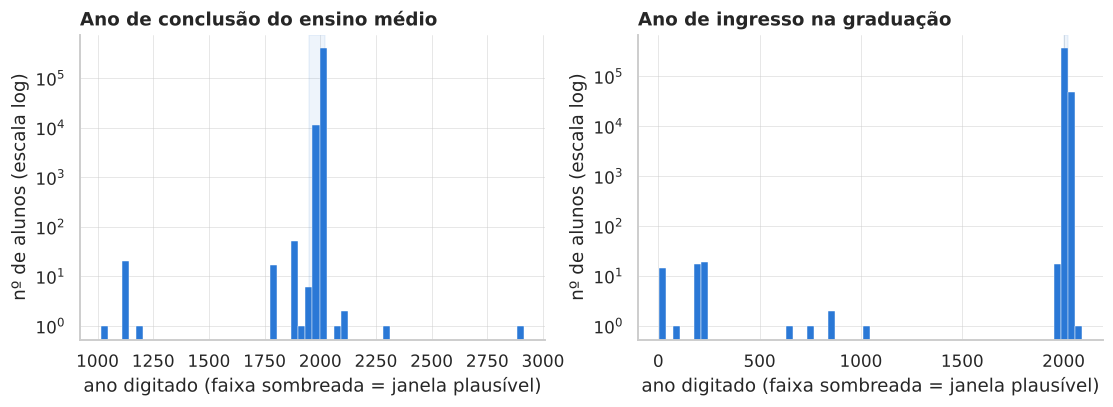

In [16]:
a2 = ler_arq(2, usecols=["ANO_FIM_EM", "ANO_IN_GRAD", "CO_TURNO_GRADUACAO"])
a2[["ANO_FIM_EM", "ANO_IN_GRAD"]] = a2[["ANO_FIM_EM", "ANO_IN_GRAD"]].apply(pd.to_numeric, errors="coerce")
JANELAS = {"ANO_FIM_EM": (1950, 2023), "ANO_IN_GRAD": (2000, 2023)}
qual = []
for c, (lo, hi) in JANELAS.items():
    s = a2[c].dropna(); fora = ((s < lo) | (s > hi))
    qual.append({"variável": c, "preenchidos": len(s), "mínimo": s.min(), "máximo": s.max(), "janela plausível": f"{lo}–{hi}", "fora da janela": int(fora.sum()), "% fora": 100 * fora.mean()})
qual.append({"variável": "NU_IDADE", "preenchidos": a6["NU_IDADE"].notna().sum(), "mínimo": a6["NU_IDADE"].min(), "máximo": a6["NU_IDADE"].max(), "janela plausível": "16–90",
             "fora da janela": int(((a6["NU_IDADE"] < 16) | (a6["NU_IDADE"] > 90)).sum()), "% fora": 100 * float(((a6["NU_IDADE"] < 16) | (a6["NU_IDADE"] > 90)).mean())})
display(pd.DataFrame(qual).style.format({"preenchidos": "{:,.0f}", "mínimo": "{:.0f}", "máximo": "{:.0f}", "% fora": "{:.3f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, c, t in zip(axes, ["ANO_FIM_EM", "ANO_IN_GRAD"], ["Ano de conclusão do ensino médio", "Ano de ingresso na graduação"]):
    lo, hi = JANELAS[c]; s = a2[c].dropna()
    ax.hist(s, bins=60, color=AZUL, edgecolor="white", linewidth=0.3); ax.set_yscale("log")
    ax.axvspan(lo, hi, color=AZUL, alpha=0.08); ax.set_title(t); ax.set_xlabel("ano digitado (faixa sombreada = janela plausível)"); ax.set_ylabel("nº de alunos (escala log)")
salvar("10_anos_digitados.png")

**Interpretação.** Ao contrário da idade (sem valores impossíveis), **os anos digitados pelo estudante têm erros evidentes**: 101 alunos informaram conclusão do ensino médio entre os anos 1016 e 2914, e 289 informaram ingresso na graduação entre os anos 4 e 2090. São poucos casos (0,03% e 0,07%), mas valores desse tamanho **distorceriam a média do curso**: um único "2914" em um curso de 20 alunos somaria mais de 40 anos à média. Por isso a Parte 2 transforma esses valores em ausentes antes de calcular `anos_entre_em_e_grad` e `anos_de_curso`.

## 1.8 Do aluno ao curso: o perfil dos concluintes se relaciona com a nota?

Aqui é onde a ideia do projeto aparece pela primeira vez. Para cada curso, calculamos a **parcela de concluintes** com certa característica (por exemplo, renda familiar acima de 6 salários mínimos) e comparamos com a **nota relativa à área** do curso. Cada ponto abaixo é um curso.

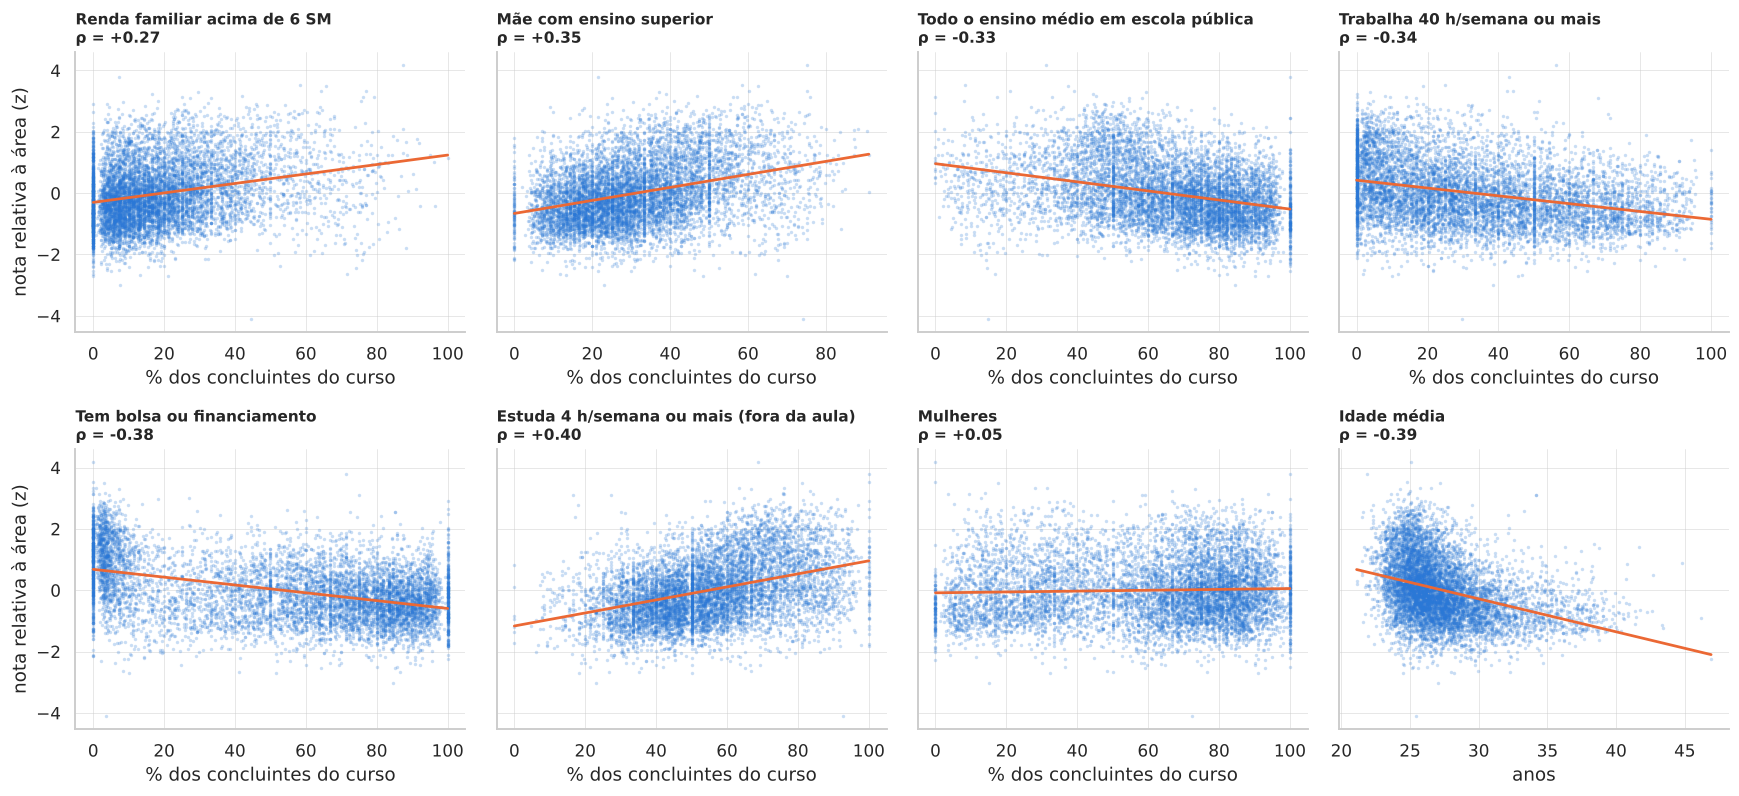

In [17]:
def share_por_curso(i, q, letras):
    d = ler_arq(i, usecols=["CO_CURSO", q]).dropna(subset=[q])
    return d[q].isin(letras).groupby(d["CO_CURSO"]).mean()

perfil = pd.DataFrame({
    "renda_acima_6sm": share_por_curso(14, "QE_I08", list("EFG")),
    "mae_superior": share_por_curso(11, "QE_I05", list("EF")),
    "escola_publica_total": share_por_curso(23, "QE_I17", list("A")),
    "trabalha_40h": share_por_curso(16, "QE_I10", list("E")),
    "com_bolsa_ou_financ": share_por_curso(17, "QE_I11", list("CDEFGHIJK")),
    "estuda_mais_de_4h": share_por_curso(29, "QE_I23", list("CDE")),
})
sexo_curso = ler_arq(5, usecols=["CO_CURSO", "TP_SEXO"]); perfil["pct_feminino"] = (sexo_curso["TP_SEXO"] == "F").groupby(sexo_curso["CO_CURSO"]).mean()
idade_curso = ler_arq(6, usecols=["CO_CURSO", "NU_IDADE"]); idade_curso["NU_IDADE"] = pd.to_numeric(idade_curso["NU_IDADE"], errors="coerce")
perfil["idade_media"] = idade_curso.groupby("CO_CURSO")["NU_IDADE"].mean()
eda = exp.join(perfil, how="left")
NOMES = {"renda_acima_6sm": "Renda familiar acima de 6 SM", "mae_superior": "Mãe com ensino superior", "escola_publica_total": "Todo o ensino médio em escola pública",
         "trabalha_40h": "Trabalha 40 h/semana ou mais", "com_bolsa_ou_financ": "Tem bolsa ou financiamento", "estuda_mais_de_4h": "Estuda 4 h/semana ou mais (fora da aula)",
         "pct_feminino": "Mulheres", "idade_media": "Idade média"}
from scipy.stats import spearmanr
fig, axes = plt.subplots(2, 4, figsize=(16, 7.4), sharey=True)
for ax, c in zip(axes.ravel(), NOMES):
    d = eda[[c, "nota_relativa"]].dropna(); rho = spearmanr(d[c], d["nota_relativa"])[0]
    fator = 100 if c != "idade_media" else 1
    ax.scatter(d[c] * fator, d["nota_relativa"], s=5, alpha=0.25, color=AZUL, linewidths=0)
    b = np.polyfit(d[c] * fator, d["nota_relativa"], 1); xs = np.array([d[c].min(), d[c].max()]) * fator; ax.plot(xs, b[0] * xs + b[1], color=LARANJA, lw=1.8)
    ax.set_title(f"{NOMES[c]}\nρ = {rho:+.2f}", fontsize=10); ax.set_xlabel("% dos concluintes do curso" if c != "idade_media" else "anos")
for ax in axes[:, 0]: ax.set_ylabel("nota relativa à área (z)")
plt.tight_layout(); salvar("11_dispersao_perfil_x_nota.png")

**Interpretação.** Cada ponto é um curso. Há associações claras com a nota relativa à área: **quanto mais concluintes estudam 4 h ou mais por semana fora da aula (ρ = +0,40) ou têm mãe com ensino superior (+0,35), maior tende a ser a nota; quanto mais concluintes têm bolsa ou financiamento (−0,38), trabalham 40 h (−0,34) ou estudaram só em escola pública (−0,33), menor tende a ser**. A idade média do curso também se associa negativamente (−0,39), enquanto o % de mulheres praticamente não se relaciona (+0,05). São correlações moderadas (|ρ| entre 0,27 e 0,40) e com muita dispersão: nenhum fator sozinho explica a nota, o que justifica combiná-los em um modelo. Também são **associações, não causas**: "ter bolsa ou financiamento" é mais comum em cursos privados (em curso público gratuito ninguém tem bolsa), então esse fator também carrega a diferença entre público e privado.

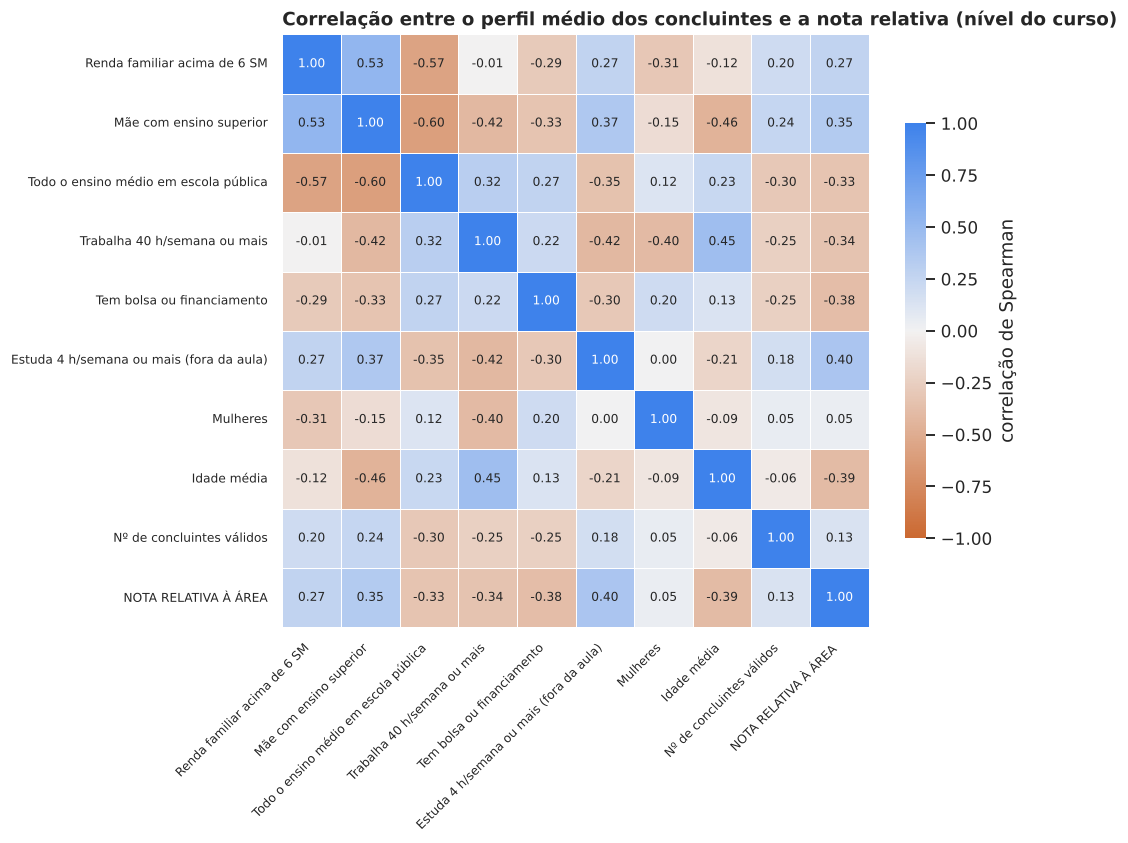

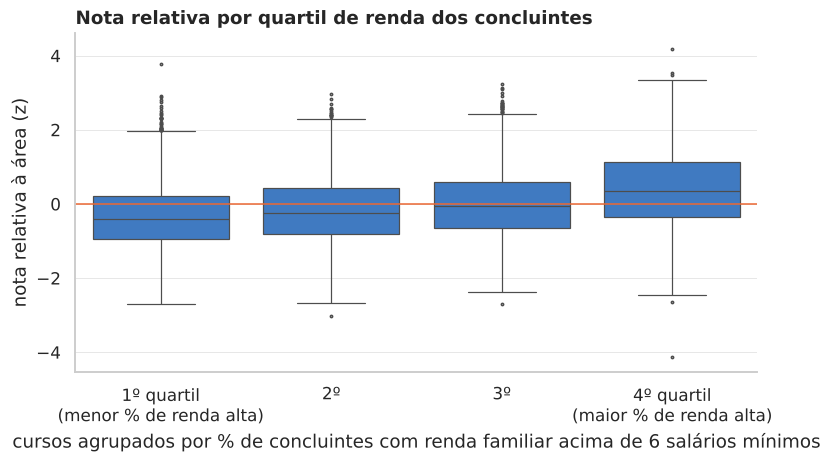

,cursos,pct_renda_alta_media,nota_relativa_mediana,nota_relativa_media
faixa_renda,,,,
1º quartil,1997,3.0,-0.41,-0.30
2º,1899,11.1,-0.25,-0.14
3º,1908,20.9,-0.07,+0.04
4º quartil,1919,43.5,+0.35,+0.41


In [18]:
cols = list(NOMES) + ["n_validos", "nota_relativa"]
rot = {**NOMES, "n_validos": "Nº de concluintes válidos", "nota_relativa": "NOTA RELATIVA À ÁREA"}
cm = eda[cols].corr(method="spearman").rename(index=rot, columns=rot)
fig, ax = plt.subplots(figsize=(8.6, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap=sns.diverging_palette(28, 255, s=85, l=55, center="light", as_cmap=True), center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax, annot_kws={"fontsize": 8}, cbar_kws={"shrink": 0.7, "label": "correlação de Spearman"})
ax.set_title("Correlação entre o perfil médio dos concluintes e a nota relativa (nível do curso)"); ax.tick_params(axis="x", rotation=45, labelsize=8); ax.tick_params(axis="y", labelsize=8)
plt.setp(ax.get_xticklabels(), ha="right"); salvar("12_correlacao_perfil_nota.png")

# Boxplot: nota relativa por faixa (quartis) de renda alta
eda["faixa_renda"] = pd.qcut(eda["renda_acima_6sm"], 4, labels=["1º quartil\n(menor % de renda alta)", "2º", "3º", "4º quartil\n(maior % de renda alta)"])
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=eda, x="faixa_renda", y="nota_relativa", color=AZUL, fliersize=1.5, linewidth=0.8, ax=ax); ax.axhline(0, color=LARANJA, lw=1)
ax.set_xlabel("cursos agrupados por % de concluintes com renda familiar acima de 6 salários mínimos"); ax.set_ylabel("nota relativa à área (z)"); ax.set_title("Nota relativa por quartil de renda dos concluintes")
salvar("13_boxplot_renda.png")
display(eda.groupby("faixa_renda", observed=True).agg(cursos=("nota_relativa", "size"), pct_renda_alta_media=("renda_acima_6sm", lambda x: 100 * x.mean()), nota_relativa_mediana=("nota_relativa", "median"), nota_relativa_media=("nota_relativa", "mean")).rename(index=lambda i: str(i).split("\n")[0]).style.format({"pct_renda_alta_media": "{:.1f}", "nota_relativa_mediana": "{:+.2f}", "nota_relativa_media": "{:+.2f}"}))

**Interpretação.** A matriz mostra duas coisas. (1) Na última linha, a relação de cada fator com a nota relativa (os mesmos valores dos gráficos de dispersão). (2) Nas demais, **os fatores estão correlacionados entre si**: cursos com muita renda alta têm mais mães com ensino superior (ρ = 0,53) e menos alunos de escola pública (−0,57); idade média e trabalho de 40 h andam juntos (0,45). Isso é multicolinearidade: o efeito "isolado" de cada fator é difícil de separar. Na modelagem isso pede **regularização** (usamos penalidade L2 na regressão logística) e cautela ao interpretar coeficientes. O boxplot por quartis de renda confirma a tendência: a mediana da nota relativa sobe de −0,41 (cursos com ≈ 3% de concluintes de renda alta) para +0,35 (≈ 43,5%), mas as caixas se sobrepõem bastante: a renda sozinha não separa os cursos.

## 1.9 Conclusões da análise exploratória

**Síntese.** 
1. **Unidade de análise = curso**, porque os arquivos só se juntam pelo `CO_CURSO`.
2. **Tarefa = classificação binária** (acima ou abaixo da mediana da área). As notas não são comparáveis entre áreas (Medicina ≈ 66 × engenharias ≈ 37), então o alvo é relativo à área.
3. **Corte de 10 concluintes válidos por curso**, o que deixa 7.723 cursos.
4. **Limpezas necessárias**: anos digitados com valores impossíveis, 9,5% sem resposta no questionário, 432 cursos sem nota válida.
5. **Há sinal nos dados**: o perfil médio dos concluintes (renda, escolaridade da mãe, escola, trabalho, horas de estudo, idade) e as características do curso (categoria, organização, modalidade, região) se associam à nota relativa, com correlações moderadas (|ρ| até ≈ 0,4). Como os fatores são correlacionados entre si, vamos usar regularização e ler os resultados como associação.
6. **Limitações**: só 28 áreas; categoria administrativa 8 sem descrição no dicionário; dados de um único ano; análise observacional (não causal).

---
# PARTE 2 · Sprint 2 — Preparação dos dados
*(Seção 3.2 – Pré-processamento)*

Nesta parte transformamos os 32 arquivos brutos em **uma tabela por curso, pronta para os algoritmos**. Todas as decisões abaixo são justificadas pela análise exploratória da Parte 1.

| # | Etapa | O que faz | Por que |
|---|---|---|---|
| 1 | **Seleção de registros** | Mantém só concluintes com `TP_PRES = 555` e `NT_GER` preenchida | Só eles têm nota válida (manual do INEP) |
| 2 | **Limpeza de valores inválidos** | Idade fora de 16–90, `ANO_FIM_EM` fora de 1950–2023, `ANO_IN_GRAD` fora de 2000–2023, percepção fora de 1–6 e intervalos negativos viram ausentes | Valores digitados pelo estudante, impossíveis |
| 3 | **Tratamento de ausentes** | Percentuais calculados só entre quem respondeu; alternativa que ninguém marcou = 0% | Evita tratar "não respondeu" como resposta |
| 4 | **Agregação aluno → curso** | Proporção de cada alternativa, médias de idade, anos etc., por `CO_CURSO` | Os arquivos só se juntam pelo curso (Parte 1) |
| 5 | **Filtro de cursos** | Mantém cursos com ≥ 10 concluintes válidos | Médias de cursos muito pequenos são instáveis |
| 6 | **Variável-alvo** | `acima_mediana` = 1 se a nota média do curso for maior que a mediana da sua área | Cada área tem sua prova; compara-se dentro da área |
| 7 | **Seleção de atributos** | Exclui notas (origem do alvo), identificadores e itens de percepção | Evita vazamento da resposta para a entrada |
| 8 | **Transformações do modelo** | Imputação, padronização, *one-hot* e atributos relativos à área, dentro de um *pipeline* | Aprendidos **só no treino** (Parte 3) |

## 2.1 Etapa 1 — Seleção de registros

In [19]:
n_tot = len(a3)
funil = pd.DataFrame([
    ("Concluintes inscritos na base", n_tot),
    ("  − ausentes, eliminados, dispensados (TP_PRES ≠ 555 e ≠ 888)", -int((~a3["TP_PRES"].isin(["555", "888"])).sum())),
    ("  − presentes com resultado desconsiderado (TP_PRES = 888)", -int((a3["TP_PRES"] == "888").sum())),
    ("  − presença 555 mas NT_GER vazia", -int(((a3["TP_PRES"] == "555") & a3["NT_GER"].isna()).sum())),
    ("= Concluintes com nota válida usados nas médias dos cursos", int(valido.sum()))], columns=["etapa", "alunos"])
assert funil["alunos"].iloc[0] + funil["alunos"].iloc[1:4].sum() == funil["alunos"].iloc[4]
display(funil.style.format({"alunos": "{:,.0f}"}).hide(axis="index"))

etapa,alunos
Concluintes inscritos na base,"406,294"
"− ausentes, eliminados, dispensados (TP_PRES ≠ 555 e ≠ 888)","-59,528"
− presentes com resultado desconsiderado (TP_PRES = 888),-38
− presença 555 mas NT_GER vazia,-209
= Concluintes com nota válida usados nas médias dos cursos,"346,519"


**Interpretação.** De 406.294 concluintes inscritos, **346.519 (85,3%)** têm resultado válido e entram no cálculo da média dos cursos. Os 59.775 excluídos são, em sua maioria, ausentes à prova (56.734) e dispensados ou eliminados (≈ 2,8 mil), além de 38 com resultado desconsiderado e 209 sem nota registrada. A exclusão é por aluno: um curso só some da análise se ficar sem alunos válidos ou abaixo do corte de 10 (etapa 5).

## 2.2 Etapas 2 a 4 — Limpeza, ausentes e agregação por curso

A função abaixo faz as três etapas de uma vez e **registra quantos valores foram alterados**. Para cada pergunta do questionário, a proporção de cada alternativa é calculada **entre quem respondeu**; quando o curso tem respondentes, as alternativas que ninguém marcou valem 0 (e não "ausente").

In [20]:
QMAP = {7: "QE_I01", 8: "QE_I02", 9: "QE_I03", 10: "QE_I04", 11: "QE_I05", 12: "QE_I06", 13: "QE_I07", 14: "QE_I08", 15: "QE_I09", 16: "QE_I10",
        17: "QE_I11", 18: "QE_I12", 19: "QE_I13", 20: "QE_I14", 21: "QE_I15", 23: "QE_I17", 24: "QE_I18", 25: "QE_I19", 26: "QE_I20", 27: "QE_I21",
        28: "QE_I22", 29: "QE_I23", 30: "QE_I24", 31: "QE_I25", 32: "QE_I26"}      # arq22 (QE16 – UF do ensino médio) fica de fora: 27 categorias, quase todas vazias por curso
LIM_IDADE, LIM_FIM_EM, LIM_IN_GRAD = (16, 90), (1950, 2023), (2000, 2023)

def construir_tabela_cursos():
    log = {}
    # (a) cadastro do curso
    a1_ = ler_arq(1); c = a1_.groupby("CO_CURSO")[ATTRS].first(); c["n_inscritos"] = a1_.groupby("CO_CURSO").size()
    # (b) notas: só alunos com resultado válido
    n3 = ler_arq(3, usecols=["CO_CURSO", "TP_PRES", "NT_GER", "NT_FG", "NT_CE"]); n3[["NT_GER", "NT_FG", "NT_CE"]] = n3[["NT_GER", "NT_FG", "NT_CE"]].apply(pd.to_numeric, errors="coerce")
    ok = (n3["TP_PRES"] == "555") & n3["NT_GER"].notna(); log["Alunos sem resultado válido (fora das médias)"] = int((~ok).sum())
    g = n3[ok].groupby("CO_CURSO"); c["n_validos"] = g.size()
    for k in ["NT_GER", "NT_FG", "NT_CE"]: c["media_" + k] = g[k].mean()
    # (c) sexo e idade
    s5 = ler_arq(5); c["pct_feminino"] = (s5["TP_SEXO"] == "F").groupby(s5["CO_CURSO"]).mean()
    s6 = ler_arq(6); s6["NU_IDADE"] = pd.to_numeric(s6["NU_IDADE"], errors="coerce")
    bad = (s6["NU_IDADE"] < LIM_IDADE[0]) | (s6["NU_IDADE"] > LIM_IDADE[1]); log["NU_IDADE fora de 16–90 → ausente"] = int(bad.sum()); s6.loc[bad, "NU_IDADE"] = np.nan
    c["idade_media"] = s6.groupby("CO_CURSO")["NU_IDADE"].mean()
    # (d) trajetória acadêmica
    s2 = ler_arq(2); s2[["ANO_FIM_EM", "ANO_IN_GRAD"]] = s2[["ANO_FIM_EM", "ANO_IN_GRAD"]].apply(pd.to_numeric, errors="coerce")
    b1 = (s2["ANO_FIM_EM"] < LIM_FIM_EM[0]) | (s2["ANO_FIM_EM"] > LIM_FIM_EM[1]); b2 = (s2["ANO_IN_GRAD"] < LIM_IN_GRAD[0]) | (s2["ANO_IN_GRAD"] > LIM_IN_GRAD[1])
    log["ANO_FIM_EM fora de 1950–2023 → ausente"] = int(b1.sum()); log["ANO_IN_GRAD fora de 2000–2023 → ausente"] = int(b2.sum())
    s2.loc[b1, "ANO_FIM_EM"] = np.nan; s2.loc[b2, "ANO_IN_GRAD"] = np.nan
    gap = s2["ANO_IN_GRAD"] - s2["ANO_FIM_EM"]; neg = gap < 0; log["Ingresso na graduação antes de concluir o ensino médio → ausente"] = int(neg.sum()); gap[neg] = np.nan
    s2["anos_entre_em_e_grad"] = gap; s2["anos_de_curso"] = 2023 - s2["ANO_IN_GRAD"]
    c["anos_entre_em_e_grad"] = s2.groupby("CO_CURSO")["anos_entre_em_e_grad"].mean(); c["anos_de_curso"] = s2.groupby("CO_CURSO")["anos_de_curso"].mean()
    c = c.join(s2.groupby("CO_CURSO")["CO_TURNO_GRADUACAO"].value_counts(normalize=True).unstack().add_prefix("turno_"))
    # (e) questionário do estudante: proporção de cada alternativa entre quem respondeu
    sem_resp = []
    for i, q in QMAP.items():
        a = ler_arq(i); sem_resp.append(a[q].isna().mean())
        c = c.join(a.dropna(subset=[q]).groupby("CO_CURSO")[q].value_counts(normalize=True).unstack().add_prefix(q + "_"))
    log["Questionário: % médio de alunos sem resposta (não entra nos percentuais)"] = round(100 * float(np.mean(sem_resp)), 1)
    for q in list(QMAP.values()) + ["turno"]:
        cq = [x for x in c.columns if x.startswith(q + "_")]; resp = c[cq].notna().any(axis=1)
        c.loc[resp, cq] = c.loc[resp, cq].fillna(0)
    # (f) percepção (escala 1–6) – guardada à parte (conjunto B de atributos)
    a4 = ler_arq(4); itens = [x for x in a4.columns if x.startswith("QE_I")]
    val = a4[itens].apply(pd.to_numeric, errors="coerce"); fora = val.notna() & ~val.isin([1, 2, 3, 4, 5, 6]); log["Percepção: respostas 7 ('não sei'), 8 ('não se aplica') ou fora de 1–6 → ausente (nº de respostas, não de alunos)"] = int(fora.values.sum())
    val = val.where(~fora); val["CO_CURSO"] = a4["CO_CURSO"]; per = val.groupby("CO_CURSO")[itens].mean()
    c["percepcao_media_geral"] = per.mean(axis=1); c = c.join(per.add_prefix("media_"))
    return c.reset_index(), pd.Series(log, name="quantidade")

t0 = time.time(); cursos_tudo, log_limpeza = construir_tabela_cursos()
print(f"Tabela por curso construída em {time.time()-t0:.0f} s: {cursos_tudo.shape[0]:,} cursos × {cursos_tudo.shape[1]} colunas")
display(log_limpeza.to_frame().style.format(lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.1f}"))

Tabela por curso construída em 19 s: 9,812 cursos × 221 colunas


,quantidade
Alunos sem resultado válido (fora das médias),"59,775"
NU_IDADE fora de 16–90 → ausente,0
ANO_FIM_EM fora de 1950–2023 → ausente,101
ANO_IN_GRAD fora de 2000–2023 → ausente,289
Ingresso na graduação antes de concluir o ensino médio → ausente,667
Questionário: % médio de alunos sem resposta (não entra nos percentuais),9.5
"Percepção: respostas 7 ('não sei'), 8 ('não se aplica') ou fora de 1–6 → ausente (nº de respostas, não de alunos)","525,465"


**Interpretação.** A tabela por curso foi construída em cerca de 20 segundos. Alterações: 101 anos de conclusão do ensino médio e 289 de ingresso na graduação inválidos viraram ausentes; 667 alunos (0,16%) informaram ingresso na graduação **antes** de concluir o ensino médio, contradição que também virou ausente; nenhuma idade era impossível. Nos itens de percepção, 525.465 respostas (≈ 3% das cerca de 17 milhões) estavam fora da escala 1–6: são os códigos 7 ("não sei responder") e 8 ("não se aplica"), tratados como ausentes e não como nota. Nas 25 perguntas do questionário, 9,5% dos alunos não responderam e ficam fora dos percentuais.

## 2.3 Etapa 5 — Filtro de cursos e Etapa 6 — Variável-alvo

Mantemos os cursos com **ao menos `MIN_ALUNOS` = 10 concluintes válidos**. A variável-alvo compara a nota média do curso com a **mediana das notas médias dos cursos da mesma área**:

$$\text{acima\_mediana}_c = \begin{cases} 1 & \text{se } \overline{NT\_GER}_c > \text{mediana}(\overline{NT\_GER}\ \text{dos cursos da área de } c)\\ 0 & \text{caso contrário} \end{cases}$$

Por construção as duas classes ficam equilibradas (cerca de 50% / 50%) dentro de cada área, o que também torna "chutar sempre a mesma classe" um *baseline* de ~50%.

mínimo de concluintes válidos,cursos mantidos
1,9380
5,8835
10,7723
20,5492
30,3779


Cursos usados na modelagem: 7,723 (de 9,812) | acima da mediana: 49.9%


,cursos,mediana_da_nota,pct_acima
area,,,
Enfermagem,896,49.6,50.0
Engenharia Civil,695,38.3,49.9
Fisioterapia,604,53.6,50.0
Farmácia,524,43.9,50.0
Nutrição,502,49.2,50.0
Arquitetura e Urbanismo,461,54.5,49.9
Odontologia,431,48.5,49.9
Biomedicina,422,40.8,50.0
Agronomia,378,50.2,50.0


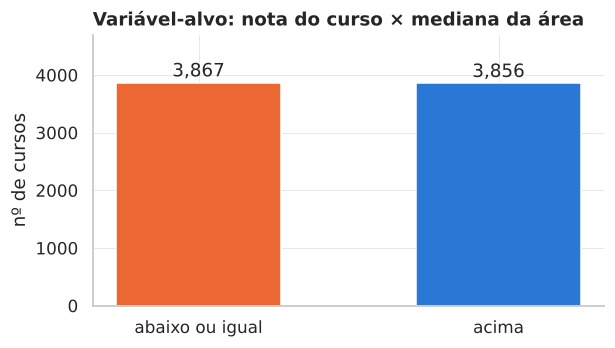

In [21]:
MIN_ALUNOS = 10
sens = pd.DataFrame({"mínimo de concluintes válidos": [1, 5, 10, 20, 30], "cursos mantidos": [int((cursos_tudo["n_validos"] >= k).sum()) for k in [1, 5, 10, 20, 30]]})
display(sens.style.hide(axis="index"))

dados = cursos_tudo[cursos_tudo["n_validos"] >= MIN_ALUNOS].copy().reset_index(drop=True)
dados["mediana_area"] = dados.groupby("CO_GRUPO")["media_NT_GER"].transform("median")
dados["acima_mediana"] = (dados["media_NT_GER"] > dados["mediana_area"]).astype(int)
dados["log_n_inscritos"] = np.log1p(dados["n_inscritos"])
dados["area"] = dados["CO_GRUPO"].map(AREAS)
print(f"Cursos usados na modelagem: {len(dados):,} (de {len(cursos_tudo):,}) | acima da mediana: {dados['acima_mediana'].mean()*100:.1f}%")

area_tab = (dados.groupby("area").agg(cursos=("CO_CURSO", "size"), mediana_da_nota=("media_NT_GER", "median"), pct_acima=("acima_mediana", "mean")).sort_values("cursos", ascending=False))
area_tab["pct_acima"] *= 100
display(area_tab.style.format({"mediana_da_nota": "{:.1f}", "pct_acima": "{:.1f}"}))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(["abaixo ou igual", "acima"], [(dados["acima_mediana"] == 0).sum(), (dados["acima_mediana"] == 1).sum()], color=[LARANJA, AZUL], width=0.55)
for k, val in enumerate([(dados["acima_mediana"] == 0).sum(), (dados["acima_mediana"] == 1).sum()]): ax.text(k, val + 110, f"{val:,}", ha="center")
ax.set_ylabel("nº de cursos"); ax.set_title("Variável-alvo: nota do curso × mediana da área"); ax.set_ylim(0, 4700)
salvar("14_variavel_alvo.png")

**Interpretação.** Restaram **7.723 cursos** (79% dos 9.812). Como esperado, as classes ficam equilibradas: 3.856 cursos "acima" (49,9%) e 3.867 "abaixo ou igual", e todas as áreas ficam entre 48% e 50% de cursos acima. Esse equilíbrio tem um benefício metodológico: acurácia de 50% equivale a "chutar" e qualquer valor acima disso é desempenho real. A tabela mostra também que algumas áreas têm poucos cursos após o filtro (Tecnologia em Segurança no Trabalho, 12; Agronegócios, 27; Gestão Hospitalar, 37): nelas a mediana é menos estável e as previsões merecem mais cautela.

## 2.4 Etapa 7 — Seleção de atributos

Os atributos de entrada (X) descrevem **o perfil médio dos concluintes** e **as características do curso**. Ficam de fora:
- as **notas** (`NT_*`, `media_NT_*`): são a origem do alvo (usá-las seria vazamento);
- os **identificadores** (`CO_CURSO`, `CO_IES`, `CO_MUNIC_CURSO`) e `n_validos` (que vem do filtro de presença);
- os **itens de percepção da prova/curso** (QE27–68): ficam em um conjunto B, testado na Parte 3 como alternativa (ganho pequeno, dentro do ruído).

> **Decisão da equipe pendente:** `EXCLUIR_COR_RACA`. A proporção de cada cor/raça (`QE_I02_*`) está incluída por padrão. Por ser uma variável sensível, a Parte 3 mede quanto ela contribui para a acurácia; se a equipe preferir, basta trocar a constante abaixo para `True`.

In [22]:
EXCLUIR_COR_RACA = False
CAT = ["CO_CATEGAD", "CO_ORGACAD", "CO_MODALIDADE", "CO_REGIAO_CURSO", "CO_UF_CURSO", "CO_GRUPO"]
QE_COLS = [c for c in dados.columns if re.fullmatch(r"QE_I\d\d_[A-K]", c)]
TURNO_COLS = sorted(c for c in dados.columns if c.startswith("turno_"))
OUTRAS = ["pct_feminino", "idade_media", "anos_entre_em_e_grad", "anos_de_curso", "log_n_inscritos"]
PERCEP = sorted(c for c in dados.columns if c.startswith("media_QE_I")) + ["percepcao_media_geral"]
NUM = [c for c in QE_COLS if not (EXCLUIR_COR_RACA and c.startswith("QE_I02_"))] + TURNO_COLS + OUTRAS

assert not any(c.startswith(("NT_", "media_NT")) for c in CAT + NUM + PERCEP)        # nenhuma nota entre as entradas
tab_attr = pd.DataFrame([
    ("Características do curso", "categórico (6)", "categoria administrativa, organização acadêmica, modalidade, região, UF e área", len(CAT)),
    ("Perfil: questionário do estudante", "numérico (proporções 0–1)", "% de concluintes em cada alternativa de 25 perguntas (renda, escolaridade dos pais, escola do ensino médio, trabalho, bolsas…)", len(QE_COLS)),
    ("Perfil: turno", "numérico (proporções 0–1)", "% de concluintes em cada turno", len(TURNO_COLS)),
    ("Perfil: demografia e trajetória", "numérico", "% feminino, idade média, anos entre ensino médio e graduação, anos de curso, log(nº de concluintes)", len(OUTRAS)),
    ("Percepção da prova/curso (conjunto B, opcional)", "numérico (1–6)", "média de cada item QE27–68 e média geral", len(PERCEP)),
], columns=["grupo", "tipo", "conteúdo", "nº de atributos"])
display(tab_attr.style.hide(axis="index"))
print(f"Entradas do modelo (conjunto A): {len(CAT)} categóricas + {len(NUM)} numéricas = {len(CAT) + len(NUM)} atributos | alvo: acima_mediana")
X, y, grupos = dados[CAT + NUM].copy(), dados["acima_mediana"].copy(), dados["CO_IES"].copy()
print("Valores ausentes restantes nas entradas:", int(X.isna().sum().sum()), "células de", X.size, f"({100*X.isna().mean().mean():.2f}%) — serão imputados dentro do pipeline")

grupo,tipo,conteúdo,nº de atributos
Características do curso,categórico (6),"categoria administrativa, organização acadêmica, modalidade, região, UF e área",6
Perfil: questionário do estudante,numérico (proporções 0–1),"% de concluintes em cada alternativa de 25 perguntas (renda, escolaridade dos pais, escola do ensino médio, trabalho, bolsas…)",156
Perfil: turno,numérico (proporções 0–1),% de concluintes em cada turno,4
Perfil: demografia e trajetória,numérico,"% feminino, idade média, anos entre ensino médio e graduação, anos de curso, log(nº de concluintes)",5
"Percepção da prova/curso (conjunto B, opcional)",numérico (1–6),média de cada item QE27–68 e média geral,43


Entradas do modelo (conjunto A): 6 categóricas + 165 numéricas = 171 atributos | alvo: acima_mediana


Valores ausentes restantes nas entradas: 0 células de 1320633 (0.00%) — serão imputados dentro do pipeline


**Interpretação.** O conjunto A tem **171 atributos de entrada**: 6 categóricos (características do curso) e 165 numéricos (156 proporções de alternativas do questionário, 4 proporções de turno e 5 medidas de demografia, trajetória e tamanho). Nenhuma coluna de nota está entre as entradas (verificado por `assert`). Depois da limpeza e das regras de agregação **não restou nenhuma célula vazia**; a imputação do *pipeline* serve apenas de salvaguarda para dados novos.

## 2.5 Etapa 8 — Transformações aplicadas dentro do *pipeline*

Estas transformações são **aprendidas apenas no conjunto de treino** (e só então aplicadas na validação/teste), para que nenhuma informação do teste vaze para o modelo:

1. **Imputação** pela mediana (para os poucos ausentes que restam).
2. **Padronização** (média 0, desvio 1): necessária para regressão logística, KNN, SVM e rede neural.
3. **One-hot** das 6 variáveis categóricas.
4. **Atributos relativos à área** — o passo principal da nossa ideia. Para cada atributo numérico, calculamos *quantos desvios-padrão o curso está acima ou abaixo da média dos cursos da mesma área*. Assim, "70% dos alunos têm renda acima de 6 salários" tem significados diferentes em Medicina e em Zootecnia, e o modelo passa a enxergar isso **sem treinar um modelo separado por área** (que, nos testes preliminares, piorou o resultado por reduzir os dados de cada modelo).

In [23]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

class RelativoAArea(BaseEstimator, TransformerMixin):
    """Transforma cada atributo numérico em z-score DENTRO da área do curso.
    Entrada: DataFrame cuja coluna `area_col` identifica a área e as demais são numéricas.
    No fit guarda média e desvio por área (e globais, para áreas ausentes no treino); no transform apenas consulta esses valores."""
    def __init__(self, area_col="CO_GRUPO"): self.area_col = area_col
    def fit(self, X, y=None):
        self.cols_ = [c for c in X.columns if c != self.area_col]
        g = X.groupby(self.area_col)[self.cols_]
        self.media_, self.dp_ = g.mean(), g.std(ddof=0).replace(0, 1).fillna(1)
        self.media_glob_, self.dp_glob_ = X[self.cols_].mean(), X[self.cols_].std(ddof=0).replace(0, 1).fillna(1)
        return self
    def transform(self, X):
        a = X[self.area_col]
        mu = self.media_.reindex(a.values).reset_index(drop=True).fillna(self.media_glob_)
        sd = self.dp_.reindex(a.values).reset_index(drop=True).fillna(self.dp_glob_)
        z = (X[self.cols_].reset_index(drop=True) - mu) / sd
        z.columns = self.get_feature_names_out()
        return z
    def get_feature_names_out(self, input_features=None): return np.array([c + "_z" for c in self.cols_])

def montar_preprocessador(cat_cols=CAT, num_cols=NUM, relativo=True, usar_num=True, area_col="CO_GRUPO"):
    """ColumnTransformer: one-hot (categóricas) + numéricas padronizadas + numéricas relativas à área."""
    blocos = []
    if cat_cols: blocos.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat_cols)))
    if usar_num and num_cols: blocos.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", keep_empty_features=True)), ("esc", StandardScaler())]), list(num_cols)))
    if relativo and num_cols: blocos.append(("rel", Pipeline([("rel", RelativoAArea(area_col)), ("imp", SimpleImputer(strategy="median", keep_empty_features=True)), ("esc", StandardScaler())]), [area_col] + list(num_cols)))
    return ColumnTransformer(blocos, verbose_feature_names_out=True)

# Demonstração (só para mostrar o efeito; nos experimentos o ajuste é feito no treino): renda familiar alta em 5 cursos de Medicina
col_demo = "QE_I08_F"
demo = RelativoAArea().fit(X[[ "CO_GRUPO", col_demo]])
exemplo = X[X["CO_GRUPO"] == "12"][["CO_GRUPO", col_demo]].head(5).copy()
exemplo["z (relativo à área)"] = demo.transform(exemplo)[col_demo + "_z"].values
exemplo["média da área"] = demo.media_.loc["12", col_demo]; exemplo["dp da área"] = demo.dp_.loc["12", col_demo]
exemplo = exemplo.rename(columns={col_demo: f"{rotulo(col_demo, 40)} (proporção)"}).drop(columns="CO_GRUPO")
display(exemplo.style.format("{:.3f}"))
pre_demo = montar_preprocessador().fit(X)
print(f"O pré-processador completo gera {len(pre_demo.get_feature_names_out())} colunas numéricas a partir dos {X.shape[1]} atributos de entrada.")

,Renda familiar: De 10 a 30 salários mín… (proporção),z (relativo à área),média da área,dp da área
23,0.402,1.113,0.271,0.118
45,0.366,0.811,0.271,0.118
46,0.466,1.654,0.271,0.118
90,0.411,1.192,0.271,0.118
91,0.435,1.394,0.271,0.118


O pré-processador completo gera 404 colunas numéricas a partir dos 171 atributos de entrada.


**Interpretação.** Exemplo: entre os cursos de Medicina, em média 27,1% dos concluintes têm renda familiar de 10 a 30 salários mínimos (desvio padrão de 11,8 pontos percentuais). Um curso com 40,2% fica a +1,11 desvio padrão da média da área; outro, com 46,6%, a +1,65. O mesmo valor poderia ser comum em outra área, e é esse ajuste que o modelo passa a enxergar. No total, o pré-processador gera **404 colunas**: 74 do *one-hot* (7 categorias administrativas, 5 organizações acadêmicas, 2 modalidades, 5 regiões, 27 UFs e 28 áreas), 165 atributos padronizados e 165 atributos relativos à área.

## 2.6 Verificações finais e arquivo gerado

In [24]:
os.makedirs("dados_processados", exist_ok=True)
saida = dados.drop(columns=["area"]).copy()
saida.to_csv("dados_processados/cursos_enade2023_modelagem.csv", index=False)
verif_final = pd.Series({
    "cursos (linhas)": len(saida), "atributos de entrada": len(CAT) + len(NUM), "cursos duplicados": int(saida["CO_CURSO"].duplicated().sum()),
    "alvo com valores ausentes": int(saida["acima_mediana"].isna().sum()), "% da classe 1 (acima da mediana)": round(100 * saida["acima_mediana"].mean(), 1),
    "colunas de nota entre as entradas": 0, "IES distintas (usadas no agrupamento da Parte 3)": int(saida["CO_IES"].nunique())})
display(verif_final.to_frame("valor").style.format(lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.1f}"))
print("Arquivo salvo em dados_processados/cursos_enade2023_modelagem.csv (", f"{os.path.getsize('dados_processados/cursos_enade2023_modelagem.csv')/1e6:.1f} MB )")

,valor
cursos (linhas),"7,723"
atributos de entrada,171
cursos duplicados,0
alvo com valores ausentes,0
% da classe 1 (acima da mediana),49.9
colunas de nota entre as entradas,0
IES distintas (usadas no agrupamento da Parte 3),"1,209"


Arquivo salvo em dados_processados/cursos_enade2023_modelagem.csv ( 21.7 MB )


---
# PARTE 3 · Sprint 3 — Algoritmos individuais
*(Seção 3.3 – Divisão dos dados · Seção 3.4 – Algoritmos individuais · Seção 3.7 – Métricas de avaliação · Seção 4.2 – Parte 2: Algoritmos individuais)*

Nesta parte treinamos e comparamos **sete configurações individuais** (um *baseline* e seis algoritmos) para prever `acima_mediana`. Os comitês de classificadores (*ensembles*) e os testes estatísticos ficam para as próximas sprints.

## 3.1 Divisão dos dados (Seção 3.3)

**Cuidado central: vazamento entre cursos da mesma instituição.** Cursos de uma mesma IES compartilham gestão, infraestrutura e perfil de público. Se um curso da IES *A* estivesse no treino e outro, parecido, da IES *A* no teste, o modelo "reconheceria" a instituição e a acurácia ficaria inflada. Por isso a divisão **mantém todos os cursos de uma IES no mesmo lado** (`StratifiedGroupKFold` agrupado por `CO_IES`) e preserva o equilíbrio das classes.

| Camada | Como | Proporção efetiva |
|---|---|---|
| **Teste (hold-out)** | 1 de 5 partes, sorteada com semente fixa; usada **uma única vez**, no final | ≈ 20% |
| **Treino** | as outras 4 partes | ≈ 80% |
| **Validação** | validação cruzada de 5 partes **dentro do treino** (mesma regra de grupos), usada para escolher hiperparâmetros | ≈ 16% por rodada (treino efetivo 64%) |

In [25]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, make_scorer, roc_curve)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_tr, idx_te = next(sgkf.split(X, y, grupos))
XB = dados[CAT + NUM + PERCEP]                                            # mesma tabela + conjunto B (só usado na análise de ablação)
X_tr, X_te, y_tr, y_te, g_tr, g_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te], grupos.iloc[idx_tr], grupos.iloc[idx_te]
assert set(g_tr).isdisjoint(set(g_te)), "uma mesma IES não pode aparecer em treino e teste"

cv_interno = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv_interno.split(X_tr, y_tr, g_tr))                          # mesmas 5 partições para todos os algoritmos
for k, (a, b) in enumerate(folds): assert set(g_tr.iloc[a]).isdisjoint(set(g_tr.iloc[b]))

div = pd.DataFrame([{"conjunto": "Treino (total)", "cursos": len(X_tr), "% do total": 100 * len(X_tr) / len(X), "IES": g_tr.nunique(), "% classe acima": 100 * y_tr.mean()},
                    {"conjunto": "  └ cada rodada: treina em", "cursos": np.mean([len(a) for a, b in folds]), "% do total": 100 * np.mean([len(a) for a, b in folds]) / len(X), "IES": np.mean([g_tr.iloc[a].nunique() for a, b in folds]), "% classe acima": 100 * np.mean([y_tr.iloc[a].mean() for a, b in folds])},
                    {"conjunto": "  └ cada rodada: valida em", "cursos": np.mean([len(b) for a, b in folds]), "% do total": 100 * np.mean([len(b) for a, b in folds]) / len(X), "IES": np.mean([g_tr.iloc[b].nunique() for a, b in folds]), "% classe acima": 100 * np.mean([y_tr.iloc[b].mean() for a, b in folds])},
                    {"conjunto": "Teste (hold-out)", "cursos": len(X_te), "% do total": 100 * len(X_te) / len(X), "IES": g_te.nunique(), "% classe acima": 100 * y_te.mean()}])
display(div.style.format({"cursos": "{:,.0f}", "% do total": "{:.1f}", "IES": "{:,.0f}", "% classe acima": "{:.1f}"}).hide(axis="index"))

pa = pd.concat([X_tr["CO_GRUPO"].value_counts(normalize=True).rename("treino"), X_te["CO_GRUPO"].value_counts(normalize=True).rename("teste")], axis=1).fillna(0) * 100
pa.index = pa.index.map(AREAS); pa["diferença (p.p.)"] = pa["teste"] - pa["treino"]
print(f"Maior diferença de participação de uma área entre treino e teste: {pa['diferença (p.p.)'].abs().max():.1f} p.p.")
display(pa.sort_values("treino", ascending=False).head(10).style.format("{:.1f}"))

conjunto,cursos,% do total,IES,% classe acima
Treino (total),"6,180",80.0,971,49.9
└ cada rodada: treina em,"4,944",64.0,777,49.9
└ cada rodada: valida em,"1,236",16.0,194,49.9
Teste (hold-out),"1,543",20.0,238,49.9


Maior diferença de participação de uma área entre treino e teste: 1.5 p.p.


,treino,teste,diferença (p.p.)
CO_GRUPO,,,
Enfermagem,11.3,12.8,1.5
Engenharia Civil,8.9,9.5,0.7
Fisioterapia,7.9,7.4,-0.5
Farmácia,6.9,6.3,-0.6
Nutrição,6.6,6.0,-0.6
Arquitetura e Urbanismo,6.0,6.0,-0.0
Odontologia,5.6,5.6,0.1
Biomedicina,5.5,5.4,-0.0
Engenharia Mecânica,5.0,4.1,-0.9


**Interpretação.** O treino ficou com **6.180 cursos (80,0%)** de 971 instituições e o teste com **1.543 (20,0%)** de 238 instituições; nenhuma IES aparece nos dois lados (verificado por `assert`, inclusive entre as partes da validação cruzada). Em cada rodada da validação, treinamos com ≈ 4.944 cursos (64% do total) e validamos com ≈ 1.236 (16%). A proporção da classe "acima" é 49,9% em todos os conjuntos, e nenhuma área muda mais de 1,5 ponto percentual de participação entre treino e teste, então o teste representa bem o conjunto. Essa divisão é mais exigente que um sorteio simples: o modelo é avaliado em instituições que nunca viu, o que dá uma estimativa mais honesta para cursos de instituições novas.

## 3.2 Algoritmos individuais e configurações (Seção 3.4)

Todos os modelos recebem **exatamente o mesmo pré-processamento** (Parte 2), montado dentro de um `Pipeline`; assim, imputação, padronização, *one-hot* e atributos relativos à área são reaprendidos apenas com o treino de cada rodada.

| Algoritmo | Ideia | Por que está aqui |
|---|---|---|
| **Baseline** (classe mais frequente) | ignora os atributos | piso de comparação (~50%) |
| **Regressão Logística** | combinação linear dos atributos → probabilidade | modelo interpretável; permite relatar associações |
| **KNN** | classifica pelos *k* cursos mais parecidos | testa se "cursos parecidos têm resultados parecidos" |
| **Árvore de Decisão** | regras do tipo "se renda > x e …" | interpretável e captura não linearidades |
| **Naive Bayes Gaussiano** | assume atributos independentes | rápido; testa o efeito de atributos correlacionados |
| **SVM (kernel RBF)** | fronteira não linear de margem máxima | bom com muitos atributos e poucos exemplos |
| **Rede Neural (MLP)** | camadas ocultas não lineares | capacidade de aprender interações |

Os hiperparâmetros foram escolhidos por **busca em grade (`GridSearchCV`)** com a validação cruzada agrupada por IES, maximizando o **F1 macro**.

In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

MODELOS = {
    "Baseline (classe mais frequente)": (DummyClassifier(), {"clf__strategy": ["most_frequent"]}),
    "Regressão Logística": (LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), {"clf__C": [0.01, 0.03, 0.1, 0.3, 1]}),
    "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [5, 15, 31], "clf__weights": ["uniform", "distance"]}),
    "Árvore de Decisão": (DecisionTreeClassifier(random_state=RANDOM_STATE), {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [1, 10, 30]}),
    "Naive Bayes (Gaussiano)": (GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]}),
    "SVM (kernel RBF)": (SVC(kernel="rbf", random_state=RANDOM_STATE), {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.001]}),
    "Rede Neural (MLP)": (MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE), {"clf__hidden_layer_sizes": [(64,), (128, 64)], "clf__alpha": [1e-4, 1e-2]}),
}
FIXOS = {"Baseline (classe mais frequente)": "—", "Regressão Logística": "penalidade L2, solver lbfgs, max_iter=3000", "KNN": "distância euclidiana",
         "Árvore de Decisão": "critério gini", "Naive Bayes (Gaussiano)": "—", "SVM (kernel RBF)": "kernel='rbf'", "Rede Neural (MLP)": "ReLU, adam, max_iter=500, early_stopping=True (10% de validação interna)"}
grade = pd.DataFrame([{"algoritmo": m, "hiperparâmetro": (k.replace("clf__", "") if p else "—"), "valores testados": (str(v) if p else "—"), "fixos": FIXOS[m]}
                      for m, (est, p) in MODELOS.items() for k, v in (p.items() if p else [(None, None)])])
display(grade.style.hide(axis="index"))
print("Combinações avaliadas:", {m: int(np.prod([len(v) for v in p.values()])) if p else 1 for m, (e, p) in MODELOS.items()}, "× 5 rodadas de validação cada")

algoritmo,hiperparâmetro,valores testados,fixos
Baseline (classe mais frequente),strategy,['most_frequent'],—
Regressão Logística,C,"[0.01, 0.03, 0.1, 0.3, 1]","penalidade L2, solver lbfgs, max_iter=3000"
KNN,n_neighbors,"[5, 15, 31]",distância euclidiana
KNN,weights,"['uniform', 'distance']",distância euclidiana
Árvore de Decisão,max_depth,"[3, 5, 8, None]",critério gini
Árvore de Decisão,min_samples_leaf,"[1, 10, 30]",critério gini
Naive Bayes (Gaussiano),var_smoothing,"[1e-09, 1e-06, 0.001, 0.1]",—
SVM (kernel RBF),C,"[0.1, 1, 10]",kernel='rbf'
SVM (kernel RBF),gamma,"['scale', 0.001]",kernel='rbf'
Rede Neural (MLP),hidden_layer_sizes,"[(64,), (128, 64)]","ReLU, adam, max_iter=500, early_stopping=True (10% de validação interna)"


Combinações avaliadas: {'Baseline (classe mais frequente)': 1, 'Regressão Logística': 5, 'KNN': 6, 'Árvore de Decisão': 12, 'Naive Bayes (Gaussiano)': 4, 'SVM (kernel RBF)': 6, 'Rede Neural (MLP)': 4} × 5 rodadas de validação cada


## 3.3 Métricas de avaliação (Seção 3.7)

A classe positiva é **"acima da mediana da área"** (1). Sejam VP/VN os acertos e FP/FN os erros de cada classe:

| Métrica | Definição | Leitura neste projeto |
|---|---|---|
| **Acurácia** | (VP + VN) / total | fração de cursos classificados corretamente. Como as classes são ~50/50, o *baseline* fica em ~50% |
| **Precisão** | VP / (VP + FP) | dos cursos que o modelo diz estarem acima da mediana, quantos realmente estão |
| **Revocação** (*recall*) | VP / (VP + FN) | dos cursos realmente acima da mediana, quantos o modelo encontra |
| **F1** | 2 · precisão · revocação / (precisão + revocação) | equilíbrio entre as duas; **F1 macro** é a média do F1 das duas classes (critério de escolha dos hiperparâmetros) |
| **AUC-ROC** | área sob a curva revocação × taxa de falsos positivos | qualidade do *ranking* de cursos, independente do limiar de 0,5 |
| **Matriz de confusão** | contagem de VP, VN, FP, FN | mostra o tipo de erro |

As métricas são calculadas (i) na **validação cruzada** do treino (média ± desvio das 5 rodadas), usada para comparar e escolher, e (ii) **uma única vez** no conjunto de teste.

## 3.4 Treinamento e resultados (Seção 4.2 – Parte 2: Algoritmos individuais)

In [27]:
SCORING = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0), "recall": "recall", "f1": "f1", "f1_macro": "f1_macro", "roc_auc": "roc_auc"}
METRICAS = ["accuracy", "precision", "recall", "f1", "f1_macro", "roc_auc"]
NOMES_MET = {"accuracy": "Acurácia", "precision": "Precisão", "recall": "Revocação", "f1": "F1", "f1_macro": "F1 macro", "roc_auc": "AUC-ROC"}

def score_continuo(modelo, Xd):
    return modelo.predict_proba(Xd)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(Xd)

def metricas_teste(modelo, Xd, yd):
    pred = modelo.predict(Xd); sc = score_continuo(modelo, Xd)
    return {"accuracy": accuracy_score(yd, pred), "precision": precision_score(yd, pred, zero_division=0), "recall": recall_score(yd, pred), "f1": f1_score(yd, pred),
            "f1_macro": f1_score(yd, pred, average="macro"), "roc_auc": roc_auc_score(yd, sc)}

buscas, val_rows, te_rows, hp_rows, tempos = {}, [], [], [], {}
for nome, (est, grade_p) in MODELOS.items():
    t0 = time.time()
    pipe = Pipeline([("pre", montar_preprocessador()), ("clf", est)])
    gs = GridSearchCV(pipe, grade_p, scoring=SCORING, refit="f1_macro", cv=folds, n_jobs=2, error_score="raise")
    gs.fit(X_tr, y_tr); tempos[nome] = time.time() - t0; buscas[nome] = gs
    i = gs.best_index_
    val_rows.append({"algoritmo": nome, **{m: gs.cv_results_[f"mean_test_{m}"][i] for m in METRICAS}, **{m + "_dp": gs.cv_results_[f"std_test_{m}"][i] for m in METRICAS}})
    te_rows.append({"algoritmo": nome, **metricas_teste(gs.best_estimator_, X_te, y_te)})
    hp_rows.append({"algoritmo": nome, "melhores hiperparâmetros": ", ".join(f"{k.replace('clf__','')}={v}" for k, v in gs.best_params_.items()) or "—", "tempo da busca (s)": tempos[nome]})
    print(f"{nome:36s} F1 macro (validação) = {gs.best_score_:.3f} | {tempos[nome]:5.0f} s | {gs.best_params_}")
val = pd.DataFrame(val_rows).set_index("algoritmo"); tes = pd.DataFrame(te_rows).set_index("algoritmo"); hps = pd.DataFrame(hp_rows).set_index("algoritmo")
os.makedirs("resultados", exist_ok=True)
val.to_csv("resultados/metricas_validacao_cruzada.csv"); tes.to_csv("resultados/metricas_teste.csv"); hps.to_csv("resultados/melhores_hiperparametros.csv")

Baseline (classe mais frequente)     F1 macro (validação) = 0.334 |     4 s | {'clf__strategy': 'most_frequent'}


Regressão Logística                  F1 macro (validação) = 0.804 |     7 s | {'clf__C': 0.01}


KNN                                  F1 macro (validação) = 0.751 |    10 s | {'clf__n_neighbors': 31, 'clf__weights': 'uniform'}


Árvore de Decisão                    F1 macro (validação) = 0.736 |    30 s | {'clf__max_depth': 8, 'clf__min_samples_leaf': 30}


Naive Bayes (Gaussiano)              F1 macro (validação) = 0.736 |     4 s | {'clf__var_smoothing': 0.1}


SVM (kernel RBF)                     F1 macro (validação) = 0.803 |    82 s | {'clf__C': 1, 'clf__gamma': 0.001}


Rede Neural (MLP)                    F1 macro (validação) = 0.799 |    14 s | {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (64,)}


In [28]:
display(Markdown("**Melhores hiperparâmetros encontrados (escolhidos na validação cruzada)**"))
display(hps.style.format({"tempo da busca (s)": "{:.0f}"}))
fmt = {m: (lambda v, m=m: v) for m in METRICAS}
tab_val = pd.DataFrame({NOMES_MET[m]: [f"{val.loc[a, m]*100:.1f} ± {val.loc[a, m+'_dp']*100:.1f}" for a in val.index] for m in METRICAS}, index=val.index)
display(Markdown("**Validação cruzada agrupada por IES (5 rodadas dentro do treino), média ± desvio padrão, em %**"))
display(tab_val)
display(Markdown("**Conjunto de teste (hold-out de ≈ 20% dos cursos, instituições nunca vistas no treino), em %**"))
display((tes.rename(columns=NOMES_MET) * 100).style.format("{:.1f}").background_gradient(cmap=sns.light_palette(AZUL, as_cmap=True), axis=0, vmin=40, vmax=100))

**Melhores hiperparâmetros encontrados (escolhidos na validação cruzada)**

,melhores hiperparâmetros,tempo da busca (s)
algoritmo,,
Baseline (classe mais frequente),strategy=most_frequent,4
Regressão Logística,C=0.01,7
KNN,"n_neighbors=31, weights=uniform",10
Árvore de Decisão,"max_depth=8, min_samples_leaf=30",30
Naive Bayes (Gaussiano),var_smoothing=0.1,4
SVM (kernel RBF),"C=1, gamma=0.001",82
Rede Neural (MLP),"alpha=0.0001, hidden_layer_sizes=(64,)",14


**Validação cruzada agrupada por IES (5 rodadas dentro do treino), média ± desvio padrão, em %**

,Acurácia,Precisão,Revocação,F1,F1 macro,AUC-ROC
algoritmo,,,,,,
Baseline (classe mais frequente),50.1 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,33.4 ± 0.0,50.0 ± 0.0
Regressão Logística,80.4 ± 2.1,81.6 ± 2.0,78.4 ± 2.5,80.0 ± 2.2,80.4 ± 2.1,89.1 ± 1.8
KNN,75.5 ± 3.2,82.5 ± 2.3,64.4 ± 5.9,72.2 ± 4.6,75.1 ± 3.4,84.0 ± 3.3
Árvore de Decisão,73.7 ± 3.1,74.8 ± 2.5,71.1 ± 5.4,72.9 ± 3.9,73.6 ± 3.2,80.9 ± 2.9
Naive Bayes (Gaussiano),73.8 ± 2.4,78.7 ± 1.4,65.3 ± 5.5,71.2 ± 3.7,73.6 ± 2.6,80.4 ± 2.2
SVM (kernel RBF),80.4 ± 2.4,82.7 ± 2.2,76.6 ± 3.0,79.6 ± 2.6,80.3 ± 2.4,89.2 ± 1.8
Rede Neural (MLP),79.9 ± 1.8,81.4 ± 1.4,77.4 ± 2.6,79.4 ± 2.0,79.9 ± 1.8,88.5 ± 1.8


**Conjunto de teste (hold-out de ≈ 20% dos cursos, instituições nunca vistas no treino), em %**

,Acurácia,Precisão,Revocação,F1,F1 macro,AUC-ROC
algoritmo,,,,,,
Baseline (classe mais frequente),50.1,0.0,0.0,0.0,33.4,50.0
Regressão Logística,81.9,82.8,80.5,81.6,81.9,90.6
KNN,74.5,82.5,61.9,70.8,74.1,84.1
Árvore de Decisão,75.1,75.3,74.5,74.9,75.1,82.7
Naive Bayes (Gaussiano),73.8,79.3,64.2,70.9,73.5,80.0
SVM (kernel RBF),81.7,83.1,79.6,81.3,81.7,90.9
Rede Neural (MLP),81.7,82.9,79.9,81.3,81.7,90.2


**Interpretação.** **Três algoritmos se destacam e empatam tecnicamente**: Regressão Logística (80,4 ± 2,1% de acurácia na validação; 81,9% no teste), SVM com kernel RBF (80,4 ± 2,4%; 81,7%) e Rede Neural (79,9 ± 1,8%; 81,7%). A diferença entre eles (< 0,5 p.p.) é muito menor que o desvio padrão entre as rodadas (≈ 2 p.p.), então não dá para apontar um vencedor sem um teste estatístico (previsto para a próxima sprint). KNN (75,5%), Árvore de Decisão (73,7%) e Naive Bayes (73,8%) ficam ≈ 6 p.p. abaixo, e o baseline fica em 50,1%, como esperado pelo equilíbrio das classes. A AUC-ROC dos três melhores é ≈ 0,89 na validação e 0,90–0,91 no teste: sorteando um curso "acima" e um "abaixo", o modelo dá maior probabilidade ao "acima" em cerca de 90% das vezes. O teste fica ≈ 1,5 p.p. acima da validação nos três melhores, variação compatível com o desvio padrão (≈ 2 p.p.) e com o fato de o modelo final ser treinado com 25% mais dados que cada rodada da validação; não há sinal de sobreajuste. Precisão e revocação são parecidas nos três melhores (≈ 83% e ≈ 80% no teste), enquanto KNN e Naive Bayes têm precisão de 79–83% mas revocação de só 62–64%: são "conservadores", raramente dizem "acima" e deixam passar muitos cursos acima da mediana.

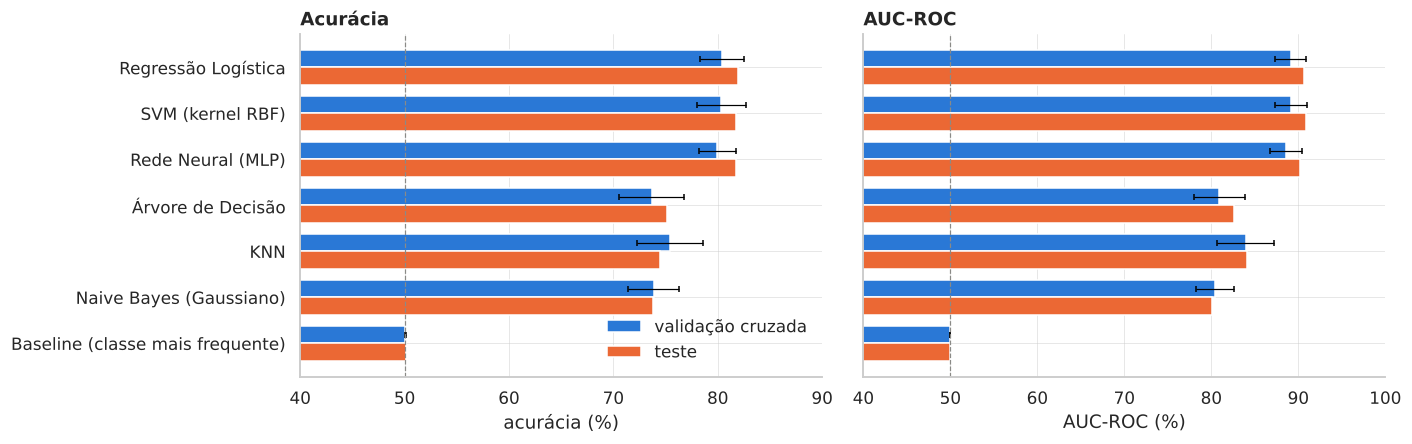

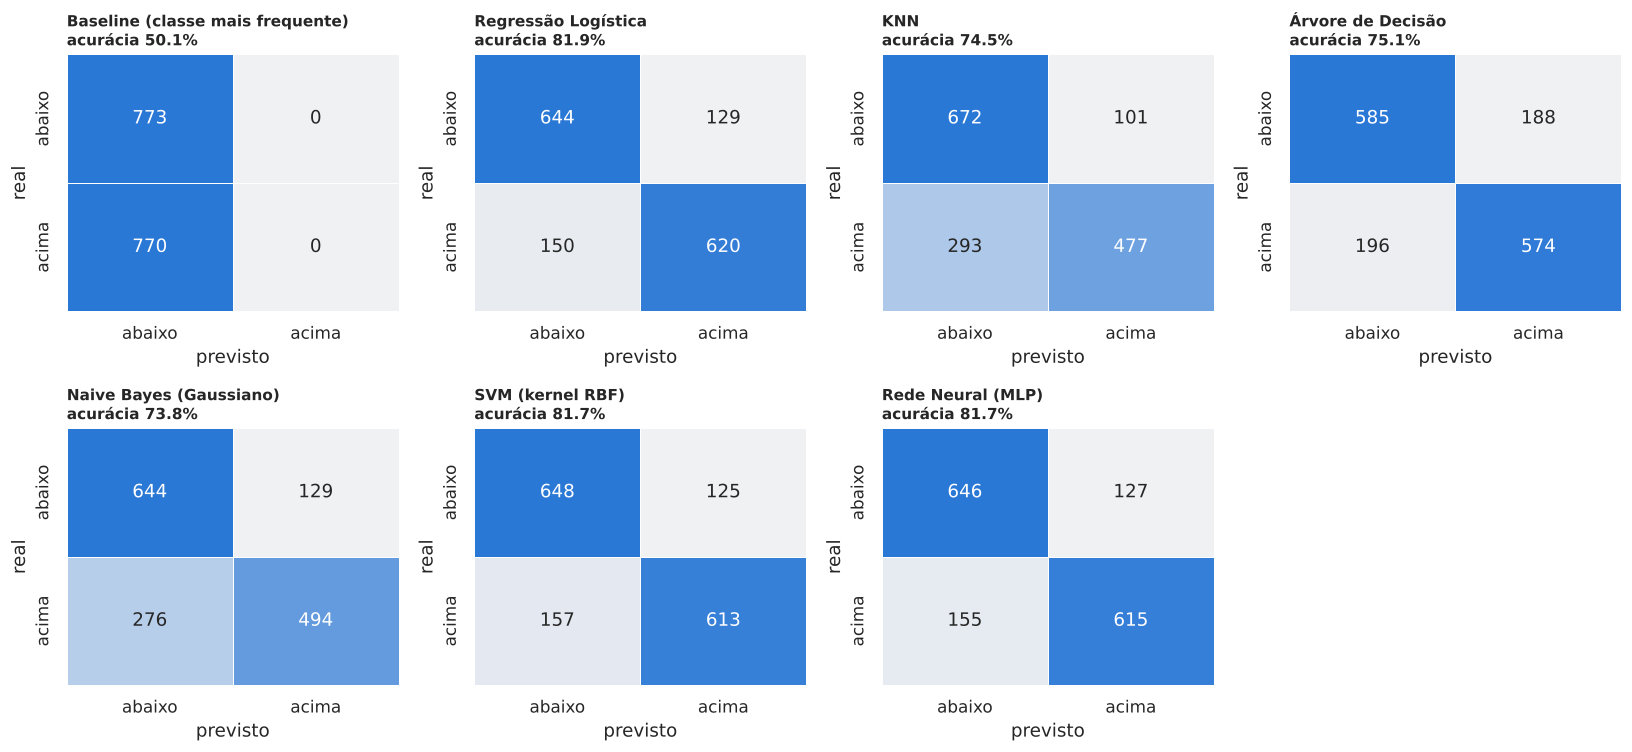

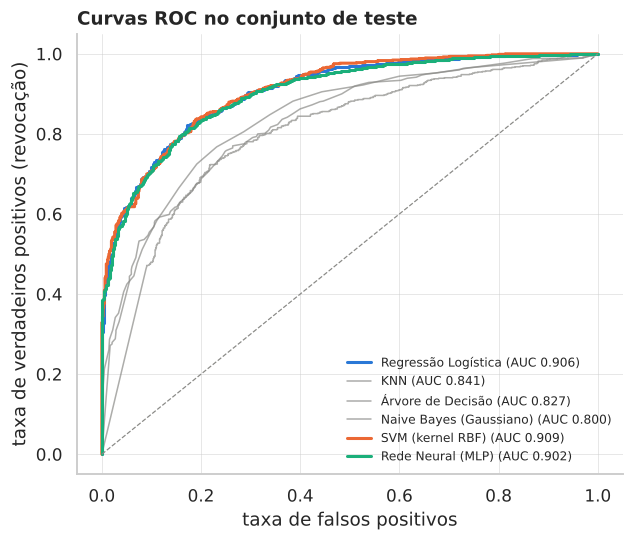

In [29]:
ordem = tes["accuracy"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
y_pos = np.arange(len(ordem)); h = 0.38
ax = axes[0]
ax.barh(y_pos + h/2, [val.loc[a, "accuracy"] * 100 for a in ordem], height=h, color=AZUL, label="validação cruzada", xerr=[val.loc[a, "accuracy_dp"] * 100 for a in ordem], error_kw=dict(lw=0.8, capsize=2))
ax.barh(y_pos - h/2, [tes.loc[a, "accuracy"] * 100 for a in ordem], height=h, color=LARANJA, label="teste")
ax.set_yticks(y_pos); ax.set_yticklabels(ordem); ax.set_xlim(40, 90); ax.set_xlabel("acurácia (%)"); ax.set_title("Acurácia"); ax.axvline(50, color=CINZA, lw=0.8, ls="--"); ax.legend(loc="lower right")
ax = axes[1]
ax.barh(y_pos + h/2, [val.loc[a, "roc_auc"] * 100 for a in ordem], height=h, color=AZUL, xerr=[val.loc[a, "roc_auc_dp"] * 100 for a in ordem], error_kw=dict(lw=0.8, capsize=2))
ax.barh(y_pos - h/2, [tes.loc[a, "roc_auc"] * 100 for a in ordem], height=h, color=LARANJA)
ax.set_xlim(40, 100); ax.set_xlabel("AUC-ROC (%)"); ax.set_title("AUC-ROC"); ax.axvline(50, color=CINZA, lw=0.8, ls="--")
plt.tight_layout(); salvar("15_comparacao_algoritmos.png")

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, nome in zip(axes.ravel(), MODELOS):
    cm_ = confusion_matrix(y_te, buscas[nome].best_estimator_.predict(X_te))
    sns.heatmap(cm_, annot=True, fmt=",d", cmap=sns.light_palette(AZUL, as_cmap=True), cbar=False, ax=ax, linewidths=0.5, xticklabels=["abaixo", "acima"], yticklabels=["abaixo", "acima"])
    ax.set_title(f"{nome}\nacurácia {tes.loc[nome, 'accuracy']*100:.1f}%", fontsize=10); ax.set_xlabel("previsto"); ax.set_ylabel("real")
axes.ravel()[-1].axis("off")
plt.tight_layout(); salvar("16_matrizes_de_confusao.png")

fig, ax = plt.subplots(figsize=(6.4, 5.2))
cores_roc = {"Regressão Logística": AZUL, "SVM (kernel RBF)": LARANJA, "Rede Neural (MLP)": "#1baf7a"}
for nome in MODELOS:
    if nome.startswith("Baseline"): continue
    fpr, tpr, _ = roc_curve(y_te, score_continuo(buscas[nome].best_estimator_, X_te))
    ax.plot(fpr, tpr, lw=2 if nome in cores_roc else 1, color=cores_roc.get(nome, CINZA), alpha=1 if nome in cores_roc else 0.7, label=f"{nome} (AUC {tes.loc[nome, 'roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=CINZA, lw=0.8, ls="--"); ax.set_xlabel("taxa de falsos positivos"); ax.set_ylabel("taxa de verdadeiros positivos (revocação)"); ax.set_title("Curvas ROC no conjunto de teste")
ax.legend(fontsize=8, loc="lower right"); salvar("17_curvas_roc.png")

**Interpretação.** Nas matrizes de confusão, a Regressão Logística acerta 644 dos 773 cursos "abaixo" e 620 dos 770 "acima", com erros equilibrados (129 falsos positivos e 150 falsos negativos). KNN (293 falsos negativos contra 101 falsos positivos) e Naive Bayes (276 contra 129) erram sobretudo ao deixar de reconhecer cursos acima da mediana. As curvas ROC mostram que Regressão Logística, SVM e MLP praticamente se sobrepõem (AUC 0,906; 0,909; 0,902), bem acima de Árvore, KNN e Naive Bayes (0,83; 0,84; 0,80).

## 3.5 Por que o melhor modelo funciona? Análises de apoio (Seção 4.2)

Para discutir as **razões** dos resultados, rodamos três verificações com a Regressão Logística (usando os mesmos *folds* e o melhor `C` encontrado): (i) **ablação** — quanto cada bloco de atributos contribui; (ii) **onde o modelo erra** (por área e por tipo de instituição); (iii) **quais atributos pesam** nas previsões. Lembrete: tudo isso mostra **associações**, não causas.

In [30]:
C_LR = buscas["Regressão Logística"].best_params_["clf__C"]
NUM_SEM_COR = [c for c in NUM if not c.startswith("QE_I02_")]
CONFIGS = {
    "Só a área do curso": dict(cat_cols=["CO_GRUPO"], num_cols=[], relativo=False, cols=CAT + NUM),
    "Só características do curso (6 categóricas)": dict(cat_cols=CAT, num_cols=[], relativo=False, cols=CAT + NUM),
    "Só perfil dos concluintes (sem área nem relativo)": dict(cat_cols=[], num_cols=NUM, relativo=False, cols=CAT + NUM),
    "Características + perfil (sem relativo à área)": dict(cat_cols=CAT, num_cols=NUM, relativo=False, cols=CAT + NUM),
    "Só perfil relativo à área (+ área)": dict(cat_cols=["CO_GRUPO"], num_cols=NUM, usar_num=False, relativo=True, cols=CAT + NUM),
    "MODELO FINAL (características + perfil + relativo à área)": dict(cat_cols=CAT, num_cols=NUM, relativo=True, cols=CAT + NUM),
    "Final + percepção da prova (conjunto B)": dict(cat_cols=CAT, num_cols=NUM + PERCEP, relativo=True, cols=CAT + NUM + PERCEP),
    "Final sem cor/raça": dict(cat_cols=CAT, num_cols=NUM_SEM_COR, relativo=True, cols=CAT + NUM),
}
abl = []
for nome, cfg in CONFIGS.items():
    cols = cfg.pop("cols"); pre = montar_preprocessador(**cfg)
    pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(C=C_LR, max_iter=3000, random_state=RANDOM_STATE))])
    r = cross_validate(pipe, XB.iloc[idx_tr][cols], y_tr, cv=folds, scoring={"accuracy": "accuracy", "f1_macro": "f1_macro", "roc_auc": "roc_auc"}, n_jobs=2)
    pipe.fit(XB.iloc[idx_tr][cols], y_tr); a_te = accuracy_score(y_te, pipe.predict(XB.iloc[idx_te][cols]))
    abl.append({"configuração (Regressão Logística)": nome, "acurácia (validação)": r["test_accuracy"].mean() * 100, "± dp": r["test_accuracy"].std() * 100,
                "F1 macro (validação)": r["test_f1_macro"].mean() * 100, "AUC (validação)": r["test_roc_auc"].mean() * 100, "acurácia (teste)": a_te * 100})
abl = pd.DataFrame(abl).set_index("configuração (Regressão Logística)"); abl.to_csv("resultados/ablacao_regressao_logistica.csv")
display(abl.style.format("{:.1f}").background_gradient(cmap=sns.light_palette(AZUL, as_cmap=True), subset=["acurácia (validação)"], vmin=40, vmax=90))

,acurácia (validação),± dp,F1 macro (validação),AUC (validação),acurácia (teste)
configuração (Regressão Logística),,,,,
Só a área do curso,47.8,0.8,47.5,46.4,45.0
Só características do curso (6 categóricas),69.1,2.3,68.9,76.8,67.6
Só perfil dos concluintes (sem área nem relativo),78.1,1.7,78.1,86.1,79.3
Características + perfil (sem relativo à área),78.4,1.9,78.4,86.6,80.5
Só perfil relativo à área (+ área),81.0,2.2,80.9,89.1,81.5
MODELO FINAL (características + perfil + relativo à área),80.4,2.1,80.4,89.1,81.9
Final + percepção da prova (conjunto B),81.2,2.1,81.2,89.4,82.0
Final sem cor/raça,80.0,2.3,80.0,88.9,81.5


**Interpretação.** Cada linha usa a mesma Regressão Logística e os mesmos *folds*, mudando apenas os atributos. (a) **Só a área** dá 47,8%, ou seja, nenhuma informação útil, como deveria ser: o alvo é relativo à área, então saber a área não diz se o curso está acima ou abaixo. (b) **Só as características do curso** (categoria, organização, modalidade, região, UF, área) já chegam a 69,1%: onde e como o curso é oferecido importa. (c) **Só o perfil dos concluintes** chega a 78,1%, o bloco mais informativo. (d) Juntar os dois (78,4%) quase não melhora o perfil isolado, o que sugere que parte do efeito das características do curso já está refletida no perfil dos alunos. (e) Os **atributos relativos à área** dão o maior salto (+2,6 p.p. sobre os 78,4%, chegando a 81,0%): comparar cada curso com os seus pares da mesma área faz diferença. O modelo final (80,4%) e a versão só com o perfil relativo (81,0%) estão empatados dentro do desvio padrão (≈ 2 p.p.); mantivemos o modelo completo porque as características do curso são úteis ao relatório. (f) Os itens de **percepção da prova** (conjunto B) elevam a validação em +0,8 p.p. e o teste em +0,1 p.p., ganho dentro do ruído; sem eles o modelo fica mais simples e não depende de uma opinião posterior à prova. (g) **Retirar cor/raça** custa só 0,4 p.p. na validação (80,0% contra 80,4%) e no teste (81,5% contra 81,9%): o modelo quase não depende desse atributo, argumento a favor de excluí-lo por ser sensível (decisão da equipe). Limitação: o hiperparâmetro `C` foi mantido no valor ótimo do modelo final em todas as linhas.

Melhor algoritmo pelo F1 macro na validação cruzada: Regressão Logística


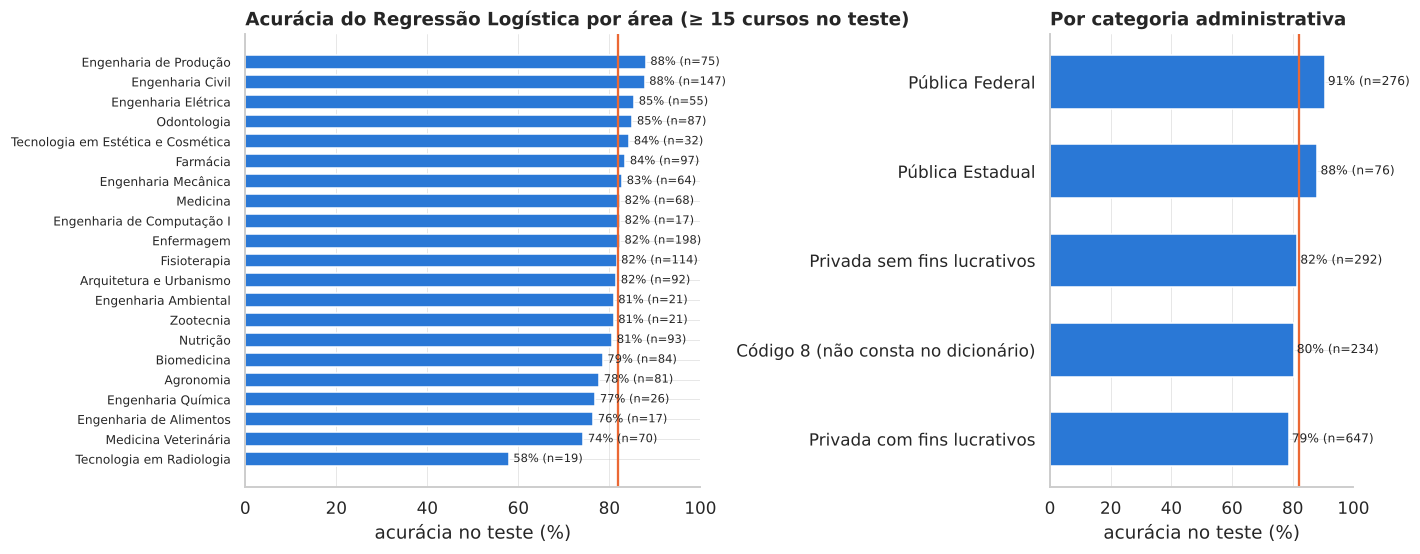

In [31]:
melhor_nome = val["f1_macro"].drop("Baseline (classe mais frequente)").idxmax()
melhor = buscas[melhor_nome].best_estimator_
print("Melhor algoritmo pelo F1 macro na validação cruzada:", melhor_nome)
dt = dados.iloc[idx_te].assign(previsto=melhor.predict(X_te), real=y_te.values)
dt["acertou"] = (dt["previsto"] == dt["real"]).astype(int)
por_area = dt.groupby("area").agg(cursos_teste=("acertou", "size"), acuracia=("acertou", "mean")).sort_values("acuracia")
por_area = por_area[por_area["cursos_teste"] >= 15]
dt["categoria"] = dt["CO_CATEGAD"].map(CATEGAD); dt["regiao"] = dt["CO_REGIAO_CURSO"].map(REGIAO)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.barh(por_area.index, por_area["acuracia"] * 100, color=AZUL, height=0.7); ax.axvline(dt["acertou"].mean() * 100, color=LARANJA, lw=1.5)
ax.set_xlim(0, 100); ax.set_xlabel("acurácia no teste (%)"); ax.set_title(f"Acurácia do {melhor_nome} por área (≥ 15 cursos no teste)"); ax.tick_params(axis="y", labelsize=8)
for k, (a_, r_) in enumerate(por_area.iterrows()): ax.text(r_["acuracia"] * 100 + 1, k, f"{r_['acuracia']*100:.0f}% (n={int(r_['cursos_teste'])})", va="center", fontsize=7.5)
ax = axes[1]
pc = dt.groupby("categoria").agg(n=("acertou", "size"), acc=("acertou", "mean")); pc = pc[pc["n"] >= 15].sort_values("acc")
ax.barh(pc.index, pc["acc"] * 100, color=AZUL, height=0.6); ax.axvline(dt["acertou"].mean() * 100, color=LARANJA, lw=1.5); ax.set_xlim(0, 100)
for k, (a_, r_) in enumerate(pc.iterrows()): ax.text(r_["acc"] * 100 + 1, k, f"{r_['acc']*100:.0f}% (n={int(r_['n'])})", va="center", fontsize=8)
ax.set_xlabel("acurácia no teste (%)"); ax.set_title("Por categoria administrativa")
plt.tight_layout(); salvar("18_erros_por_area_categoria.png")

**Interpretação.** O modelo acerta entre 74% e 88% dos cursos na maioria das áreas (Engenharia de Produção e Civil: 88%; Medicina Veterinária: 74%), sempre perto da média geral de 81,9% (linha laranja). O pior resultado é em Tecnologia em Radiologia (58%), mas são só 19 cursos no teste, então a estimativa é muito incerta. Por categoria administrativa, o modelo acerta mais nos cursos públicos federais (91%) e estaduais (88%) do que nos privados com e sem fins lucrativos (79% e 82%). Uma possível razão é que os cursos públicos ficam bem mais longe da mediana (nota relativa ≈ +1, seção 1.5), o que os torna mais fáceis de separar, enquanto entre os privados as notas se sobrepõem mais.

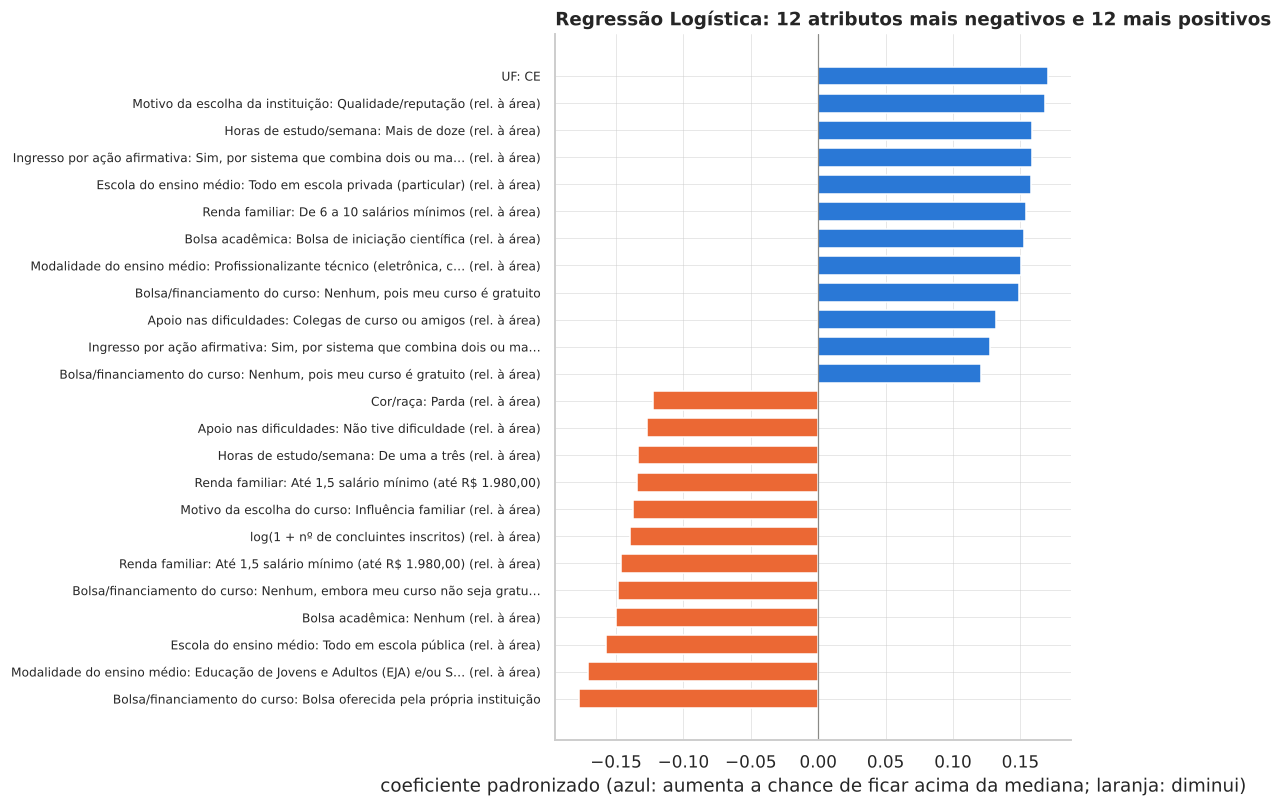

404 atributos transformados | 6 com |coeficiente| < 0,001


In [32]:
lr = buscas["Regressão Logística"].best_estimator_
nomes = lr.named_steps["pre"].get_feature_names_out(); coef = lr.named_steps["clf"].coef_[0]
def rotulo_feature(n):
    bloco_, resto = n.split("__", 1)
    if bloco_ == "cat":
        for col, dic in [("CO_GRUPO", AREAS), ("CO_CATEGAD", CATEGAD), ("CO_ORGACAD", ORGACAD), ("CO_MODALIDADE", MODALIDADE), ("CO_REGIAO_CURSO", REGIAO), ("CO_UF_CURSO", UF)]:
            if resto.startswith(col + "_"): return f"{ {'CO_GRUPO': 'Área', 'CO_CATEGAD': 'Categoria', 'CO_ORGACAD': 'Organização', 'CO_MODALIDADE': 'Modalidade', 'CO_REGIAO_CURSO': 'Região', 'CO_UF_CURSO': 'UF'}[col] }: {dic.get(resto[len(col)+1:], resto[len(col)+1:])}"
    return rotulo(resto, 70)
imp = pd.DataFrame({"atributo": [rotulo_feature(n) for n in nomes], "coeficiente": coef}).sort_values("coeficiente")
top = pd.concat([imp.head(12), imp.tail(12)])
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(top["atributo"], top["coeficiente"], color=[LARANJA if v < 0 else AZUL for v in top["coeficiente"]], height=0.7)
ax.axvline(0, color=CINZA, lw=0.8); ax.set_xlabel("coeficiente padronizado (azul: aumenta a chance de ficar acima da mediana; laranja: diminui)")
ax.set_title("Regressão Logística: 12 atributos mais negativos e 12 mais positivos"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); salvar("19_coeficientes_regressao_logistica.png")
imp.sort_values("coeficiente", ascending=False).to_csv("resultados/coeficientes_regressao_logistica.csv", index=False)
print(f"{len(imp)} atributos transformados | {int((imp['coeficiente'].abs() < 1e-3).sum())} com |coeficiente| < 0,001")

**Interpretação.** Os coeficientes ajudam a *ler* o modelo, com cautela. (1) São pequenos (≤ 0,18) porque o melhor `C` (0,01) é uma regularização forte, adequada para 404 atributos muito correlacionados. (2) Cada fator aparece duas vezes (valor bruto e relativo à área) e fatores parecidos dividem o peso entre si, então **a lista não é um ranking de importância nem de causas**. Mesmo assim, o padrão é coerente com a análise exploratória: aumentam a chance de o curso ficar acima da mediana da área mais alunos de escola privada, renda de 6 a 10 salários, mais de 12 horas de estudo por semana, bolsa de iniciação científica, escolha da instituição por qualidade/reputação e curso gratuito (público); diminuem a chance mais alunos de escola pública, renda de até 1,5 salário, bolsa da própria instituição, EJA/supletivo no ensino médio, ausência de bolsa acadêmica e influência familiar na escolha do curso. A UF Ceará tem o maior coeficiente positivo (controlando pelos demais atributos, cursos cearenses tendem a ficar acima da mediana da área) e a proporção de alunos pardos aparece entre os mais negativos: isso mostra por que incluir cor/raça é uma decisão sensível, pois a associação provavelmente reflete desigualdades de contexto (renda, tipo de escola, região) e não deve ser lida como efeito da cor/raça.

## 3.6 Discussão (Seção 4.2)

**Discussão dos resultados.** **Qual algoritmo foi melhor?** Regressão Logística, SVM e MLP formam o grupo de cabeça (≈ 80% na validação, ≈ 82% no teste, AUC ≈ 0,90). Escolhemos a **Regressão Logística** como referência por três razões: tem o maior F1 macro na validação (80,4%, praticamente empatada com a SVM, 80,3%), é a mais simples e rápida (segundos de busca, contra mais de um minuto da SVM) e é a única que gera coeficientes interpretáveis, necessários para o relatório por curso.

**Possíveis razões para os resultados.** (i) O sinal está espalhado em muitas variáveis correlacionadas de efeito pequeno (≈ 400 colunas para ≈ 5 mil cursos de treino), situação em que a regressão regularizada é muito eficiente. (ii) Os atributos relativos à área já deixam a relação aproximadamente linear, então a flexibilidade extra de SVM e rede neural não traz ganho mensurável. (iii) A Árvore de Decisão fragmenta os dados com regras do tipo "se… então" e perde informação quando o efeito está espalhado por muitos fatores. (iv) O KNN sofre com a alta dimensionalidade: as distâncias entre cursos ficam pouco discriminativas. (v) O Naive Bayes supõe atributos independentes, o que as correlações vistas na análise exploratória (renda × escolaridade da mãe × escola pública) violam. Essas são hipóteses coerentes com os resultados, ainda não testadas isoladamente.

**Limitações.** A nota de cada curso é média de poucos alunos; o modelo mostra associações, não causas; o teste tem 1.543 cursos (erro-padrão da acurácia ≈ 1 p.p.); o desempenho varia por área e é menor nos cursos privados; e as áreas pequenas (menos de 50 cursos) são pouco confiáveis.

**Próximos passos.** Comitês de classificadores, testes estatísticos entre os modelos e a geração do relatório por curso.

---
# Fechamento · mapa das entregas e próximos passos

| Entrega pedida | Onde está neste notebook |
|---|---|
| **Sprint 1** · descrição da base (formato, tamanho, estrutura, origem, nº de instâncias e atributos, tipos, ausentes) · Seção 3.1 | Parte 1 · seções 1.1 e 1.2 |
| **Sprint 1** · histogramas, dispersão, boxplots, correlação, com interpretações · Seção 4.1 | Parte 1 · seções 1.3 a 1.9 |
| **Sprint 1** · objetivo da análise e tipo de tarefa (classificação) | Cabeçalho e Parte 2 (variável-alvo) |
| **Sprint 2** · etapas de pré-processamento e código · Seção 3.2 | Parte 2 · seções 2.1 a 2.6 (e `dados_processados/`) |
| **Sprint 3** · divisão treino/validação/teste · Seção 3.3 | Parte 3 · seção 3.1 |
| **Sprint 3** · algoritmos e hiperparâmetros · Seção 3.4 | Parte 3 · seção 3.2 e tabela de melhores hiperparâmetros |
| **Sprint 3** · métricas · Seção 3.7 | Parte 3 · seção 3.3 |
| **Sprint 3** · resultados e discussão · Seção 4.2 | Parte 3 · seções 3.4 a 3.6 (e `resultados/`) |

**Ficam fora do notebook:** quadro Kanban no Trello, Seção 2.7 (Trabalhos Relacionados), redação e revisão do documento, e o registro das atividades.

**Próximos passos do projeto:** comitês de classificadores (*ensembles*) e testes estatísticos entre os modelos; função que gera o **relatório por curso** (curso X comparado à média dos cursos acima e abaixo da mediana da sua área, por tema).